# Question 2: Motion or Memory?

## Stage 1: Environment and dataset verification

**Goal:** record the environment, load Moving MNIST, verify the prescribed video splits, and inspect one training video.

### 1. Import packages and record the environment

Use the installed packages initially. Recording their versions will help reproduce the experiments later.

In [1]:
import json
import platform
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
import torchvision
from torch.utils.data import Subset

environment = {
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "cuda_available": torch.cuda.is_available(),
    "torch_cuda_version": torch.version.cuda,
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
}

print(json.dumps(environment, indent=2))

{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "numpy": "2.1.3",
  "matplotlib": "3.10.0",
  "cuda_available": true,
  "torch_cuda_version": "13.0",
  "gpu_name": "NVIDIA A100-SXM4-40GB"
}


### 2. Connect Drive and create storage folders

Approve Colab's Drive connection when prompted. This keeps the downloaded dataset and saved outputs available across runtime sessions.

The project files will be stored in `MyDrive/DL4STG_PA2`, with separate `data` and `outputs` folders. The environment information is saved as `environment_stage1.json`.

In [2]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/DL4STG_PA2")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

for directory in (DATA_DIR, OUTPUT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

environment_path = OUTPUT_DIR / "environment_stage1.json"
environment_path.write_text(
    json.dumps(environment, indent=2),
    encoding="utf-8",
)

print("Project folder:", PROJECT_DIR)
print("Dataset folder:", DATA_DIR)
print("Environment saved to:", environment_path)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/DL4STG_PA2
Dataset folder: /content/drive/MyDrive/DL4STG_PA2/data
Environment saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/environment_stage1.json


### 3. Download and inspect Moving MNIST

`split=None` returns complete videos. Torchvision's built-in `"train"` and `"test"` options split **frames within videos**, so we define our own video splits in the next cell.

Each returned video has axes **(time, channels, height, width)**. We expect 10,000 videos, each with shape `(20, 1, 64, 64)`.

The normalization function converts one video at a time to `float32` intensities in `[0, 1]`. This avoids making a float32 copy of the entire dataset.

See the [Torchvision MovingMNIST documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MovingMNIST.html).

In [3]:
def normalize_video(video):
    """Convert one uint8 video to float32 intensities in [0, 1]."""
    return video.to(dtype=torch.float32).div(255.0)


videos = torchvision.datasets.MovingMNIST(
    root=str(DATA_DIR),
    split=None,
    download=True,
    transform=normalize_video,
)

example_video = videos[0]

assert len(videos) == 10_000, "Unexpected number of videos."
assert example_video.shape == (20, 1, 64, 64), "Unexpected video shape."
assert example_video.dtype == torch.float32, "Unexpected dtype."
assert torch.isfinite(example_video).all(), "Found non-finite values."
assert 0.0 <= example_video.min().item()
assert example_video.max().item() <= 1.0

print("Number of videos:", len(videos))
print("One video shape:", tuple(example_video.shape))
print("Axis meanings: (time, channels, height, width)")
print("One video dtype:", example_video.dtype)
print(
    "Example intensity range:",
    (example_video.min().item(), example_video.max().item()),
)
print("Dataset checks passed.")

Number of videos: 10000
One video shape: (20, 1, 64, 64)
Axis meanings: (time, channels, height, width)
One video dtype: torch.float32
Example intensity range: (0.0, 1.0)
Dataset checks passed.


### 4. Define the prescribed video splits

Split by original **video index**, as required by the assignment:

| Split | Original video indices | Number of videos |
| --- | --- | --- |
| Training | 0-7,999 | 8,000 |
| Validation | 8,000-8,999 | 1,000 |
| Test | 9,000-9,999 | 1,000 |

`Subset` references selected videos in the original dataset without copying them. Training examples will be shuffled during training; these split memberships stay fixed.

In [4]:
train_videos = Subset(videos, range(0, 8_000))
val_videos = Subset(videos, range(8_000, 9_000))
test_videos = Subset(videos, range(9_000, 10_000))

assert (
    len(train_videos),
    len(val_videos),
    len(test_videos),
) == (8_000, 1_000, 1_000)

splits = {
    "train": train_videos,
    "validation": val_videos,
    "test": test_videos,
}

for name, subset in splits.items():
    first_index = subset.indices[0]
    last_index = subset.indices[-1]
    print(
        f"{name:10s}: {len(subset):5d} videos | "
        f"original indices {first_index}-{last_index}"
    )

print("Split checks passed.")

train     :  8000 videos | original indices 0-7999
validation:  1000 videos | original indices 8000-8999
test      :  1000 videos | original indices 9000-9999
Split checks passed.


### 5. Display all 20 frames of one training video

Python indexes frames from zero; the plot labels them **1-20**, matching the assignment.

Look for two handwritten digits moving across the frames. This is a dataset inspection plot; the assignment's **Figure 1** will be the optical-flow analysis later.

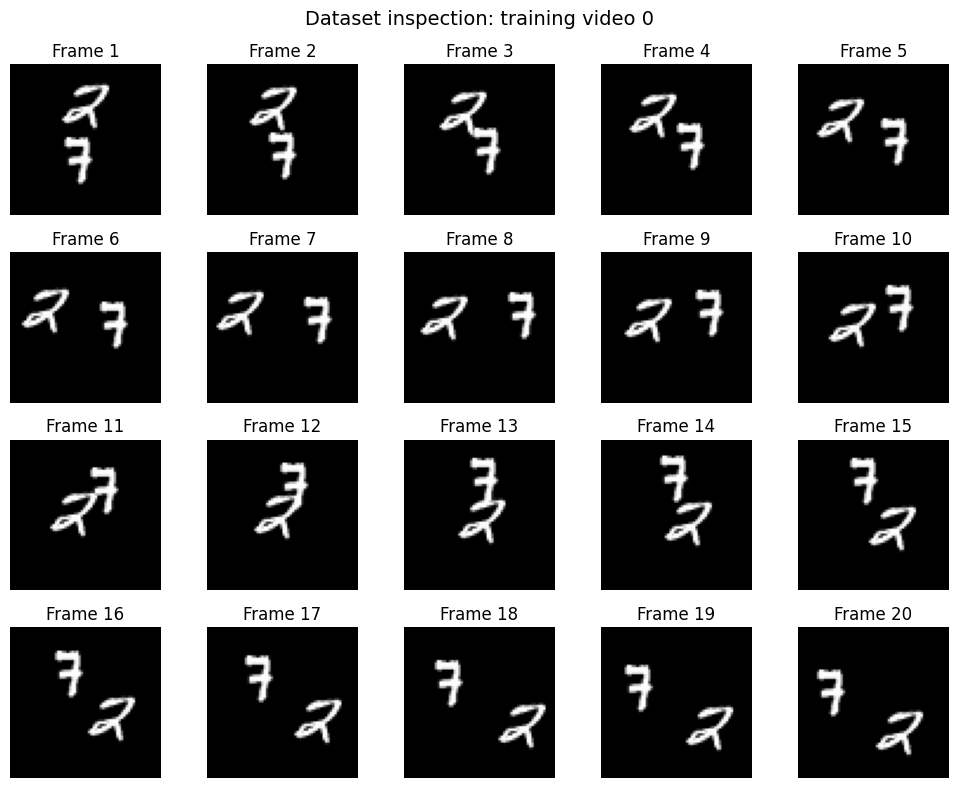

In [5]:
video = train_videos[0]

fig, axes = plt.subplots(4, 5, figsize=(10, 8))

for frame_index, ax in enumerate(axes.flat):
    ax.imshow(
        video[frame_index, 0].numpy(),
        cmap="gray",
        vmin=0.0,
        vmax=1.0,
    )
    ax.set_title(f"Frame {frame_index + 1}")
    ax.axis("off")

fig.suptitle("Dataset inspection: training video 0", fontsize=14)
fig.tight_layout()
plt.show()

## Stage 2: Transformations, forecasting windows, and Table 1

**Goal:** implement the same functions that later training and evaluation will call, and verify every check in Table 1 (assignment pages 5-6).

### 6. Define mirror and rotation

Only the last two axes are spatial: `(..., height, width)`. All leading axes, such as time, channel, or batch, keep their order.

- `mirror(x)` flips the width axis, giving a left-right reflection.
- `rotate(x)` applies one 90-degree anticlockwise rotation.
- `rotate(x, k=-1)` applies the inverse rotation.

These functions work on a full video or a batch of windows without changing frame order. They rearrange intensities without interpolation.

References: [torch.flip](https://docs.pytorch.org/docs/2.11/generated/torch.flip.html) and [torch.rot90](https://docs.pytorch.org/docs/2.11/generated/torch.rot90.html).

In [5]:
def mirror(x):
    """Reflect the last spatial axis (width); preserve leading axes."""
    return torch.flip(x, dims=(-1,))


def rotate(x, k=1):
    """Rotate the last two spatial axes anticlockwise k quarter-turns."""
    return torch.rot90(x, k=k, dims=(-2, -1))

### 7. Define valid starts and forecasting windows

`start` uses the assignment's **one-based frame numbers**. Conversion to Python's zero-based indices happens inside `make_window`.

For speed `k` and start `t`:

- Input frames: `t, t+k, ..., t+4k`.
- Candidate target frames: `t+5k, ..., t+9k`.
- A target exists only if its frame number is at most 20.

Two training protocols use different allowed starts:

| Protocol | Speed | Allowed starts |
| --- | --- | --- |
| Normal-speed training (A and B) | 1 | 1-11 |
| Speed-augmented training (C and D) | 1 | 1-14 |
| Speed-augmented training (C and D) | 2 | 1-8 |
| Speed-augmented training (C and D) | 3 | 1-2 |

The latest required frame is `t + 9k` when all five targets are required, and `t + 6k` when at least two targets are required. This gives the allowed ranges above.

`make_window` returns:

| Return value | Shape | Meaning |
| --- | --- | --- |
| `inputs` | `(5, 1, 64, 64)` | Five observed frames |
| `targets` | `(5, 1, 64, 64)` | Available targets followed by zero placeholders |
| `target_mask` | `(5,)` | Boolean indicator of which targets exist |

**The zero placeholders are not observations.** Fixed target shapes let different speeds share a batch; the mask must exclude placeholders from every loss and metric. At 3x and `start=1`, the mask is `[True, True, False, False, False]`.

Later training code must sample starts from the appropriate protocol. The window function permits any start with five inputs and at least two real targets; this includes the extra starts needed by C and D.

In [6]:
def allowed_start_frames(speed=1, speed_augmented=False):
    """Return valid one-based starts for the specified training protocol."""
    if speed not in (1, 2, 3):
        raise ValueError("speed must be 1, 2, or 3.")
    if not speed_augmented and speed != 1:
        raise ValueError("Normal-speed training permits only speed=1.")

    last_required_offset = 6 if speed_augmented else 9
    last_start = 20 - last_required_offset * speed
    return range(1, last_start + 1)


def window_frame_numbers(start=1, speed=1):
    """Return real input/target frame numbers, using frames 1-20."""
    if not isinstance(start, int) or start < 1:
        raise ValueError("start must be a positive integer frame number.")
    if speed not in (1, 2, 3):
        raise ValueError("speed must be 1, 2, or 3.")

    input_frames = [start + i * speed for i in range(5)]
    target_frames = [
        start + i * speed
        for i in range(5, 10)
        if start + i * speed <= 20
    ]

    if input_frames[-1] > 20 or len(target_frames) < 2:
        raise ValueError("A window needs five inputs and at least two targets.")

    return input_frames, target_frames


def make_window(video, start=1, speed=1):
    """Return five inputs, five padded targets, and a valid-target mask."""
    if tuple(video.shape) != (20, 1, 64, 64):
        raise ValueError("Expected a video with shape (20, 1, 64, 64).")

    input_frames, target_frames = window_frame_numbers(start, speed)
    input_indices = [frame - 1 for frame in input_frames]
    target_indices = [frame - 1 for frame in target_frames]

    inputs = video[input_indices]
    targets = video.new_zeros((5, *video.shape[1:]))
    targets[:len(target_indices)] = video[target_indices]
    target_mask = (
        torch.arange(5, device=video.device) < len(target_indices)
    )

    return inputs, targets, target_mask

### 8. Run the exact Table 1 checks

Use the random video, single-pixel marker, and frame-number video specified in the assignment. Marker coordinates use **zero-based indices**, while the window checks use frame numbers **1-20**.

For (a)-(c), both conditions must hold:

1. Maximum absolute difference is exactly zero.
2. `torch.equal` returns `True`.

Marker checks distinguish a width flip from a height flip and anticlockwise rotation from clockwise rotation. Frame-number checks detect incorrect temporal selection.

The checks call the functions defined above; later experiments will reuse those same functions.

In [8]:
import pandas as pd
from IPython.display import display

table1_rows = []
exact_equality_checks = {}


def check_exact(label, actual, expected):
    max_difference = (actual - expected).abs().max().item()
    equal = torch.equal(actual, expected)

    table1_rows.append({
        "Check": label,
        "Expected": 0,
        "Yours": max_difference,
    })
    exact_equality_checks[label] = equal

    assert max_difference == 0.0, f"{label}: nonzero difference."
    assert equal, f"{label}: torch.equal returned False."


torch.manual_seed(0)
random_video = torch.rand(20, 1, 64, 64)

check_exact(
    "(a) max|M(M(x)) - x|",
    mirror(mirror(random_video)),
    random_video,
)

rotated_four_times = random_video
for _ in range(4):
    rotated_four_times = rotate(rotated_four_times)

check_exact(
    "(b) max|R^4(x) - x|",
    rotated_four_times,
    random_video,
)
check_exact(
    "(c) max|MRM(x) - R^-1(x)|",
    mirror(rotate(mirror(random_video))),
    rotate(random_video, k=-1),
)

marker_video = torch.zeros(20, 1, 64, 64)
marker_video[7, 0, 10, 20] = 1

for label, transformed, expected_location in [
    ("(d) bright pixel of M(p)", mirror(marker_video), (7, 10, 43)),
    ("(e) bright pixel of R(p)", rotate(marker_video), (7, 43, 10)),
]:
    positions = torch.nonzero(transformed, as_tuple=False)
    assert tuple(positions.shape) == (1, 4), "Expected one bright pixel."
    frame, channel, row, column = positions[0].tolist()
    actual_location = (frame, row, column)

    assert channel == 0
    assert actual_location == expected_location, label

    table1_rows.append({
        "Check": label,
        "Expected": str(expected_location),
        "Yours": str(actual_location),
    })

frame_number_video = (
    torch.arange(1, 21, dtype=torch.float32)
    .view(20, 1, 1, 1)
    .expand(20, 1, 64, 64)
    .clone()
)

expected_windows = {
    1: ([1, 2, 3, 4, 5], [6, 7, 8, 9, 10]),
    2: ([1, 3, 5, 7, 9], [11, 13, 15, 17, 19]),
    3: ([1, 4, 7, 10, 13], [16, 19]),
}

for label, speed in [("(f)", 1), ("(g)", 2), ("(h)", 3)]:
    inputs, targets, target_mask = make_window(
        frame_number_video, start=1, speed=speed,
    )
    input_numbers = inputs[:, 0, 0, 0].to(torch.int64).tolist()
    target_numbers = targets[target_mask, 0, 0, 0].to(torch.int64).tolist()
    expected_inputs, expected_targets = expected_windows[speed]

    assert input_numbers == expected_inputs
    assert target_numbers == expected_targets
    assert target_mask.dtype == torch.bool
    assert tuple(targets.shape) == (5, 1, 64, 64)
    assert target_mask.tolist() == [
        horizon < len(expected_targets) for horizon in range(5)
    ]
    assert torch.count_nonzero(targets[~target_mask]).item() == 0

    expected_text = (
        ", ".join(map(str, expected_inputs))
        + " / "
        + ", ".join(map(str, expected_targets))
    )
    actual_text = (
        ", ".join(map(str, input_numbers))
        + " / "
        + ", ".join(map(str, target_numbers))
    )
    table1_rows.append({
        "Check": f"{label} {speed}x input / target frames",
        "Expected": expected_text,
        "Yours": actual_text,
    })

table1 = pd.DataFrame(table1_rows, columns=["Check", "Expected", "Yours"])
display(table1)

print("Exact equality checks:")
for label, equal in exact_equality_checks.items():
    print(f"  {label}: torch.equal = {equal}")

print("All eight Table 1 checks passed.")

,Check,Expected,Yours
0,(a) max|M(M(x)) - x|,0,0.0
1,(b) max|R^4(x) - x|,0,0.0
2,(c) max|MRM(x) - R^-1(x)|,0,0.0
3,(d) bright pixel of M(p),"(7, 10, 43)","(7, 10, 43)"
4,(e) bright pixel of R(p),"(7, 43, 10)","(7, 43, 10)"
5,(f) 1x input / target frames,"1, 2, 3, 4, 5 / 6, 7, 8, 9, 10","1, 2, 3, 4, 5 / 6, 7, 8, 9, 10"
6,(g) 2x input / target frames,"1, 3, 5, 7, 9 / 11, 13, 15, 17, 19","1, 3, 5, 7, 9 / 11, 13, 15, 17, 19"
7,(h) 3x input / target frames,"1, 4, 7, 10, 13 / 16, 19","1, 4, 7, 10, 13 / 16, 19"


Exact equality checks:
  (a) max|M(M(x)) - x|: torch.equal = True
  (b) max|R^4(x) - x|: torch.equal = True
  (c) max|MRM(x) - R^-1(x)|: torch.equal = True
All eight Table 1 checks passed.


### 9. Check the latest allowed starts and save results

Table 1 checks `start=1`. These extra diagnostics check the last allowed start under each training protocol, including partial target windows at 1x and 2x.

This diagnostic table is **not** the assignment's Table 2. Table 2 will contain model A's baseline results.

After every check passes, save Table 1 as CSV and the detailed checks as JSON in the persistent output folder.

In [9]:
assert list(allowed_start_frames()) == list(range(1, 12))
for speed, last_start in [(1, 14), (2, 8), (3, 2)]:
    assert list(allowed_start_frames(speed, speed_augmented=True)) == (
        list(range(1, last_start + 1))
    )

boundary_cases = [
    ("A/B", 1, 11, [16, 17, 18, 19, 20]),
    ("C/D", 1, 14, [19, 20]),
    ("C/D", 2, 8, [18, 20]),
    ("C/D", 3, 2, [17, 20]),
]
boundary_rows = []

for protocol, speed, start, expected_targets in boundary_cases:
    inputs, targets, target_mask = make_window(
        frame_number_video, start=start, speed=speed,
    )
    actual_targets = targets[target_mask, 0, 0, 0].to(torch.int64).tolist()

    assert tuple(inputs.shape) == (5, 1, 64, 64)
    assert actual_targets == expected_targets
    assert target_mask.tolist() == [
        horizon < len(expected_targets) for horizon in range(5)
    ]
    assert torch.count_nonzero(targets[~target_mask]).item() == 0

    boundary_rows.append({
        "Protocol": protocol,
        "Speed": speed,
        "Last start": start,
        "Real target frames": actual_targets,
        "Target mask": target_mask.tolist(),
    })

display(pd.DataFrame(boundary_rows))

table1_path = OUTPUT_DIR / "table1.csv"
checks_path = OUTPUT_DIR / "table1_checks.json"

table1.to_csv(table1_path, index=False)
checks_path.write_text(
    json.dumps(
        {
            "table1": table1_rows,
            "exact_equality": exact_equality_checks,
            "boundary_checks": boundary_rows,
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("Stage 2 checks passed.")
print("Table 1 saved to:", table1_path)
print("Detailed checks saved to:", checks_path)

,Protocol,Speed,Last start,Real target frames,Target mask
0,A/B,1,11,"[16, 17, 18, 19, 20]","[True, True, True, True, True]"
1,C/D,1,14,"[19, 20]","[True, True, False, False, False]"
2,C/D,2,8,"[18, 20]","[True, True, False, False, False]"
3,C/D,3,2,"[17, 20]","[True, True, False, False, False]"


Stage 2 checks passed.
Table 1 saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/table1.csv
Detailed checks saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/table1_checks.json


## Stage 3: Training-set motion statistics and Figure 1

**Goal:** estimate the directions and speeds represented in the training videos, using exactly the optical-flow protocol on assignment page 6. These observations support Q2.1 and Q2.2.

Stage 2 has passed the shared Table 1, equality, and boundary checks. Run this stage after the earlier definitions in the same Colab runtime.

We use the **first 50 training videos**, with 19 consecutive frame pairs per video: **950 pairs in total**. OpenCV's Farneback calculation runs on the CPU. No model is trained or evaluated here.

The code first measures motion, then builds the histograms, then saves the figure and measurements. Plot changes therefore do not require rerunning optical flow.

### 10. Set up optical flow and pixel selection

Optical flow estimates a displacement vector `(dx, dy)` at every pixel between two frames:

- `dx` is displacement along columns, positive to the right.
- `dy` is displacement along rows, positive downward.

The required OpenCV settings are equivalent to:

```python
cv2.calcOpticalFlowFarneback(prev, next, None, 0.5, 3, 15, 3, 5, 1.2, 0)
```

We restore the normalized frames to `uint8` intensities using multiplication by 255 and rounding. Rounding prevents conversion back to integers from accidentally truncating a value just below an integer.

Keep a pixel only when **both frames have intensity greater than 51 at that same location**, and the estimated speed is **strictly greater than 0.5 pixels/frame**. No warping of the second frame's intensity mask is used: the handout specifies the same location.

Direction is measured with `atan2(-dy, dx)`, wrapped into `[0, 360)` degrees, so right is 0 degrees and up is 90 degrees. The minus sign changes downward-positive image coordinates into upward-positive angle coordinates.

If importing `cv2` fails, stop and share the error before changing the environment.

Reference: [OpenCV Farneback documentation](https://docs.opencv.org/4.x/dc/d6b/group__video__track.html).

In [10]:
import cv2
from time import perf_counter

FARNEBACK_PARAMS = {
    "pyr_scale": 0.5,
    "levels": 3,
    "winsize": 15,
    "iterations": 3,
    "poly_n": 5,
    "poly_sigma": 1.2,
    "flags": 0,
}
NUM_FLOW_VIDEOS = 50


def select_flow_samples(previous, next_frame, flow):
    """Return directions and speeds passing the handout's pixel mask."""
    dx = flow[..., 0]
    dy = flow[..., 1]
    speed = np.hypot(dx, dy)

    keep = (
        (previous > 51)
        & (next_frame > 51)
        & (speed > 0.5)
    )

    directions = np.mod(
        np.degrees(np.arctan2(-dy[keep], dx[keep])),
        360.0,
    )
    return directions, speed[keep]


print("OpenCV version:", cv2.__version__)
print("Farneback settings:", FARNEBACK_PARAMS)
print("Pixels must have intensity > 51 in both frames and speed > 0.5.")

OpenCV version: 5.0.0
Farneback settings: {'pyr_scale': 0.5, 'levels': 3, 'winsize': 15, 'iterations': 3, 'poly_n': 5, 'poly_sigma': 1.2, 'flags': 0}
Pixels must have intensity > 51 in both frames and speed > 0.5.


### 11. Pool samples from all 950 frame pairs

Read training videos 0-49 in their original order. Each video supplies frame pairs (1, 2), (2, 3), ..., (19, 20).

A retained pixel contributes one sample. We pool all such samples across all pairs, rather than averaging separate video histograms or medians. Frames and videos with more retained pixels consequently contribute more samples, as the handout requires.

The 2x and 3x values printed below are **scaled reference displacements** based on the measured 1x median. They are not additional optical-flow measurements; bounces and estimation errors can affect apparent displacements between sampled frames.

In [11]:
assert list(train_videos.indices[:NUM_FLOW_VIDEOS]) == list(
    range(NUM_FLOW_VIDEOS)
), "Expected the first 50 original training videos."

direction_chunks = []
speed_chunks = []
pair_records = []
flow_started = perf_counter()

for video_index in range(NUM_FLOW_VIDEOS):
    normalized_frames = train_videos[video_index][:, 0].cpu().numpy()
    frames_uint8 = np.rint(normalized_frames * 255.0).astype(np.uint8)
    assert frames_uint8.shape == (20, 64, 64)

    for frame_index in range(19):
        previous = np.ascontiguousarray(frames_uint8[frame_index])
        next_frame = np.ascontiguousarray(frames_uint8[frame_index + 1])

        flow = cv2.calcOpticalFlowFarneback(
            previous,
            next_frame,
            None,
            **FARNEBACK_PARAMS,
        )
        assert flow.shape == (64, 64, 2)
        assert np.isfinite(flow).all(), "Optical flow contains non-finite values."

        directions, speeds = select_flow_samples(previous, next_frame, flow)
        direction_chunks.append(directions)
        speed_chunks.append(speeds)
        pair_records.append({
            "video_index": video_index,
            "from_frame": frame_index + 1,
            "to_frame": frame_index + 2,
            "kept_pixels": int(speeds.size),
        })

    if (video_index + 1) % 10 == 0:
        print(f"Processed {video_index + 1}/{NUM_FLOW_VIDEOS} videos.")

flow_seconds = perf_counter() - flow_started
flow_directions_deg = np.concatenate(direction_chunks)
flow_speeds = np.concatenate(speed_chunks)
flow_pair_counts = pd.DataFrame(pair_records)

num_pairs = len(pair_records)
num_kept = int(flow_speeds.size)
median_speed = float(np.median(flow_speeds)) if num_kept else float("nan")

assert num_pairs == 950
assert num_kept > 0, "No pixels survived the required mask."
assert num_kept == int(flow_pair_counts["kept_pixels"].sum())
assert flow_directions_deg.shape == flow_speeds.shape
assert np.isfinite(flow_speeds).all()
assert np.isfinite(flow_directions_deg).all()
assert np.all(flow_speeds > 0.5)
assert np.all((flow_directions_deg >= 0.0) & (flow_directions_deg <= 360.0))

print()
print("Consecutive frame pairs:", num_pairs)
print(f"Total kept pixel samples: {num_kept:,}")
print(f"Median 1x flow speed: {median_speed:.3g} pixels/frame")
print(f"Scaled 2x reference: {2 * median_speed:.3g} pixels/frame")
print(f"Scaled 3x reference: {3 * median_speed:.3g} pixels/frame")
print(f"Optical-flow calculation time: {flow_seconds:.2f} seconds")

Processed 10/50 videos.
Processed 20/50 videos.
Processed 30/50 videos.
Processed 40/50 videos.
Processed 50/50 videos.

Consecutive frame pairs: 950
Total kept pixel samples: 103,050
Median 1x flow speed: 3.32 pixels/frame
Scaled 2x reference: 6.64 pixels/frame
Scaled 3x reference: 9.95 pixels/frame
Optical-flow calculation time: 1.37 seconds


In [12]:
# Confirm that the only out-of-range values are exactly 360.
assert np.all(
    (flow_directions_deg >= 0.0)
    & (flow_directions_deg <= 360.0)
)

boundary = flow_directions_deg == 360.0
print("Angles affected by boundary rounding:", int(boundary.sum()))

# Convert first: float32 would round the corrected value back to 360.
flow_directions_deg = flow_directions_deg.astype(np.float64)
flow_directions_deg[boundary] = np.nextafter(360.0, 0.0)

assert np.all(
    (flow_directions_deg >= 0.0)
    & (flow_directions_deg < 360.0)
)

print("Angle-range check passed.")
print("Consecutive frame pairs:", num_pairs)
print(f"Total kept pixel samples: {num_kept:,}")
print(f"Median 1x flow speed: {median_speed:.3g} pixels/frame")
print(f"Scaled 2x reference: {2 * median_speed:.3g} pixels/frame")
print(f"Scaled 3x reference: {3 * median_speed:.3g} pixels/frame")

Angles affected by boundary rounding: 38
Angle-range check passed.
Consecutive frame pairs: 950
Total kept pixel samples: 103,050
Median 1x flow speed: 3.32 pixels/frame
Scaled 2x reference: 6.64 pixels/frame
Scaled 3x reference: 9.95 pixels/frame


### 12. Generate Figure 1

For each histogram, divide the count in each bin by the **total number of retained samples**. The bar heights therefore sum to one. We do not use a probability-density histogram.

- **Panel (a):** 18 direction bins, each 20 degrees wide. A horizontal reference line at `1/18` shows the fraction per bin for a uniform direction distribution.
- **Panel (b):** 30 equal-width speed bins covering the observed speeds, with the pooled median marked.

The caption records the number of retained samples and the median speed. The retained sample count counts pixel observations across frame pairs; a pixel location may contribute in several pairs.

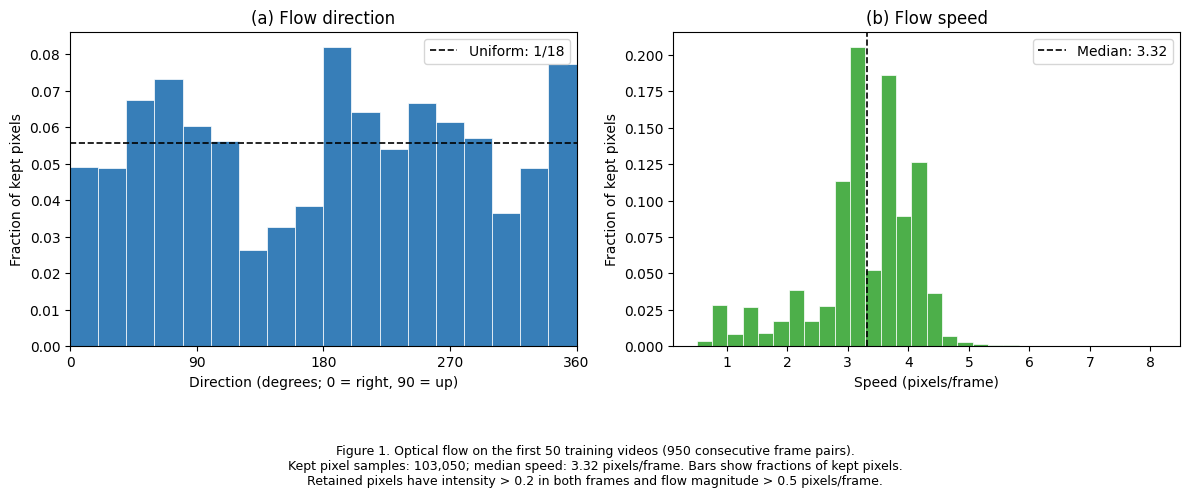

Figure 1. Optical flow on the first 50 training videos (950 consecutive frame pairs).
Kept pixel samples: 103,050; median speed: 3.32 pixels/frame. Bars show fractions of kept pixels.
Retained pixels have intensity > 0.2 in both frames and flow magnitude > 0.5 pixels/frame.


In [13]:
direction_edges = np.arange(0.0, 361.0, 20.0)
direction_counts, _ = np.histogram(
    flow_directions_deg, bins=direction_edges,
)
direction_fractions = direction_counts / num_kept

speed_counts, speed_edges = np.histogram(flow_speeds, bins=30)
speed_fractions = speed_counts / num_kept

assert direction_counts.sum() == num_kept
assert speed_counts.sum() == num_kept
assert np.isclose(direction_fractions.sum(), 1.0)
assert np.isclose(speed_fractions.sum(), 1.0)

figure1_caption = (
    "Figure 1. Optical flow on the first 50 training videos "
    "(950 consecutive frame pairs).\n"
    f"Kept pixel samples: {num_kept:,}; median speed: "
    f"{median_speed:.3g} pixels/frame. Bars show fractions of kept pixels.\n"
    "Retained pixels have intensity > 0.2 in both frames "
    "and flow magnitude > 0.5 pixels/frame."
)

flow_figure, flow_axes = plt.subplots(1, 2, figsize=(12, 5))

flow_axes[0].bar(
    direction_edges[:-1],
    direction_fractions,
    width=np.diff(direction_edges),
    align="edge",
    color="#377eb8",
    edgecolor="white",
    linewidth=0.5,
)
flow_axes[0].axhline(
    1.0 / 18.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Uniform: 1/18",
)
flow_axes[0].set(
    title="(a) Flow direction",
    xlabel="Direction (degrees; 0 = right, 90 = up)",
    ylabel="Fraction of kept pixels",
    xlim=(0, 360),
    xticks=[0, 90, 180, 270, 360],
)
flow_axes[0].legend()

flow_axes[1].bar(
    speed_edges[:-1],
    speed_fractions,
    width=np.diff(speed_edges),
    align="edge",
    color="#4daf4a",
    edgecolor="white",
    linewidth=0.5,
)
flow_axes[1].axvline(
    median_speed,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=f"Median: {median_speed:.3g}",
)
flow_axes[1].set(
    title="(b) Flow speed",
    xlabel="Speed (pixels/frame)",
    ylabel="Fraction of kept pixels",
)
flow_axes[1].legend()

flow_figure.text(
    0.5, 0.015, figure1_caption,
    ha="center", va="bottom", fontsize=9,
)
flow_figure.tight_layout(rect=(0, 0.18, 1, 1))
plt.show()

print(figure1_caption)

### Q2.1 — Training motion statistics

Figure 1(a) displays a histogram of optical-flow directions. We can observe that each direction range has samples; however, the bars are of different heights. Thus, the directions are not equally common in the examined training videos, and mirroring or rotation can change their relative frequencies. Nevertheless, transformed trajectories generally move in directions already represented in the data. These directions would therefore likely be familiar, although this does not guarantee that a model will successfully predict the transformed videos.

From Figure 1(b), a typical flow speed is around 3-4 pixels/frame, with a median of 3.32 pixels/frame. Scaling the unrounded median gives nominal displacement references of 6.64 and 9.95 pixels per observed step for 2x and 3x playback respectively. These are scaled references derived from the original measurements, rather than separately measured flow medians for faster playback.

Optical flow can be unreliable where digits overlap because the estimator assigns one displacement vector to each image location. If two overlapping digits have different motions, this vector may not represent either motion accurately. Such errors could affect both the histogram and the median speed. Depending on the degree of overlap and how many such examples occur, uncertainty remains regarding the size of this bias.

### Q2.2 — Effects of the transformations

For mirroring and rotation, the digit appearance changes, and the motion directions also change. Mirroring reverses the horizontal component of motion, while rotation turns each direction by 90°. However, the speeds remain the same. Thus, the flow-speed histogram should remain largely unchanged, while the direction distribution may be affected.

For speed-up, the digit's shape remains the same because we retain existing frames at larger intervals. However, the displacement between successive observations becomes much larger. Thus, this transformation changes the observed motion speeds while preserving the digit shapes.

These transformations provide useful controlled comparisons. Mirroring and rotation examine changes in appearance and orientation while preserving speed, whereas speed-up examines faster motion while preserving digit shape. Comparing the model's behavior under these transformations helps investigate whether failures are associated with appearance and orientation changes or with larger movements between observations.

### 13. Save Figure 1 and the underlying measurements

Save a high-resolution PNG, a compressed NumPy file containing the pooled samples, a JSON summary, per-pair sample counts, and the caption.

To revise labels or plotting choices, rerun the plotting and saving cells using the measurements already in memory. You can also restore the pooled samples from the saved NumPy file in a later session.

The saved JSON includes OpenCV's version and all Farneback settings. The per-pair counts make the pooling procedure auditable; they do not identify overlapping digits.

In [14]:
figure1_path = OUTPUT_DIR / "figure1_motion_statistics.png"
samples_path = OUTPUT_DIR / "figure1_flow_samples.npz"
summary_path = OUTPUT_DIR / "figure1_summary.json"
pair_counts_path = OUTPUT_DIR / "figure1_pair_counts.csv"
caption_path = OUTPUT_DIR / "figure1_caption.txt"

flow_figure.savefig(figure1_path, dpi=300, bbox_inches="tight")
np.savez_compressed(
    samples_path,
    directions_deg=flow_directions_deg,
    speeds_pixels_per_frame=flow_speeds,
)
flow_pair_counts.to_csv(pair_counts_path, index=False)
caption_path.write_text(figure1_caption, encoding="utf-8")

flow_summary = {
    "environment": {**environment, "opencv": cv2.__version__},
    "training_video_indices": list(range(NUM_FLOW_VIDEOS)),
    "num_frame_pairs": num_pairs,
    "kept_pixel_samples": num_kept,
    "median_speed_pixels_per_frame": median_speed,
    "scaled_2x_reference": 2 * median_speed,
    "scaled_3x_reference": 3 * median_speed,
    "scaled_reference_note": (
        "Multiples of the measured 1x median, not new flow measurements."
    ),
    "farneback_parameters": FARNEBACK_PARAMS,
    "selection": {
        "intensity_uint8_strictly_greater_than": 51,
        "intensity_required_in_both_frames_at_same_location": True,
        "flow_speed_strictly_greater_than": 0.5,
    },
    "direction_histogram": {
        "edges_degrees": direction_edges.tolist(),
        "counts": direction_counts.tolist(),
        "fractions": direction_fractions.tolist(),
    },
    "speed_histogram": {
        "edges_pixels_per_frame": speed_edges.tolist(),
        "counts": speed_counts.tolist(),
        "fractions": speed_fractions.tolist(),
    },
    "calculation_seconds": flow_seconds,
}
summary_path.write_text(
    json.dumps(flow_summary, indent=2),
    encoding="utf-8",
)

for saved_path in (
    figure1_path, samples_path, summary_path, pair_counts_path, caption_path,
):
    print("Saved:", saved_path)

print("Stage 3 measurements and Figure 1 saved.")

Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/figure1_motion_statistics.png
Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/figure1_flow_samples.npz
Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/figure1_summary.json
Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/figure1_pair_counts.csv
Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/figure1_caption.txt
Stage 3 measurements and Figure 1 saved.


## Stage 4: Model A implementation and correctness checks

**Goal:** implement the exact baseline, verify its parameter count and nine-step rollout, check the masked loss, and perform one diagnostic optimizer step.

The model created below is called `check_model`. It is disposable: official training will construct fresh models with seeds 0 and 1.

### 14. Define one ConvLSTM cell

Each cell stores a hidden state `h` and a memory state `c`. Its convolution takes the current input concatenated with the previous hidden state, and produces four groups of channels in the exact order `i, f, o, g`:

- Input gate `sigmoid(i)`: how much candidate memory to add.
- Forget gate `sigmoid(f)`: how much previous memory to keep.
- Output gate `sigmoid(o)`: how much memory to expose in the hidden state.
- Candidate `tanh(g)`: the proposed memory update.

The equations directly implement those in the handout. There are no peephole connections or additional layers. All convolutions keep PyTorch's default initialization, including their biases.

The seed helper will be reused when we set up full training. Setting a seed here initializes the diagnostic model reproducibly; official training resets the seed separately for each run.

In [7]:
import random
from torch import nn
import torch.nn.functional as F


def seed_everything(seed):
    """Seed the random-number generators used by this assignment."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class ConvLSTMCell(nn.Module):
    def __init__(self, input_channels, hidden_channels=64):
        super().__init__()
        self.hidden_channels = hidden_channels
        self.gates = nn.Conv2d(
            in_channels=input_channels + hidden_channels,
            out_channels=4 * hidden_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=True,
        )

    def forward(self, current_input, state):
        previous_h, previous_c = state
        combined = torch.cat((current_input, previous_h), dim=1)
        i, f, o, g = self.gates(combined).chunk(4, dim=1)

        new_c = (
            torch.sigmoid(f) * previous_c
            + torch.sigmoid(i) * torch.tanh(g)
        )
        new_h = torch.sigmoid(o) * torch.tanh(new_c)
        return new_h, new_c

### 15. Define the complete forecaster and nine-step rollout

A frame changes shape as follows, with `B` denoting the batch size:

`(B, 1, 64, 64)` -> pixel unshuffle -> `(B, 16, 16, 16)` -> ConvLSTM 1 -> `(B, 64, 16, 16)` -> ConvLSTM 2 -> `(B, 64, 16, 16)` -> 1x1 convolution -> `(B, 16, 16, 16)` -> pixel shuffle and sigmoid -> `(B, 1, 64, 64)`.

Pixel unshuffle rearranges each 4x4 patch into channels without learning weights; pixel shuffle reverses the rearrangement. New hidden and memory states start at zero **inside every forward call**.

The forecaster accepts only the five observed frames. Targets are supplied separately to the loss function.

| Update | Input | Output used in the forecast? |
| --- | --- | --- |
| 1-4 | Observed frames 1-4 | No |
| 5 | Observed frame 5 | Yes: horizon 1 |
| 6-9 | Previous predicted frame | Yes: horizons 2-5 |

`return_trace=True` exposes the actual input/output tensors at each update for inspection. Normal training calls use the default `False`.

References: [pixel unshuffle](https://docs.pytorch.org/docs/2.11/generated/torch.nn.functional.pixel_unshuffle.html) and [Conv2d](https://docs.pytorch.org/docs/2.11/generated/torch.nn.Conv2d.html).

In [8]:
class ConvLSTMForecaster(nn.Module):
    def __init__(self):
        super().__init__()
        self.cell1 = ConvLSTMCell(input_channels=16, hidden_channels=64)
        self.cell2 = ConvLSTMCell(input_channels=64, hidden_channels=64)
        self.readout = nn.Conv2d(64, 16, kernel_size=1, bias=True)

    def forward(self, inputs, return_trace=False):
        if inputs.ndim != 5 or tuple(inputs.shape[1:]) != (5, 1, 64, 64):
            raise ValueError("Expected inputs with shape (B, 5, 1, 64, 64).")
        if not inputs.is_floating_point():
            raise TypeError("Input frames must be floating-point tensors.")

        batch_size = inputs.shape[0]
        state_shape = (batch_size, 64, 16, 16)
        h1 = inputs.new_zeros(state_shape)
        c1 = inputs.new_zeros(state_shape)
        h2 = inputs.new_zeros(state_shape)
        c2 = inputs.new_zeros(state_shape)

        forecast_frames = []
        trace_inputs = []
        trace_outputs = []

        for step_index in range(9):
            if step_index < 5:
                frame = inputs[:, step_index]
            else:
                # Preserve the graph: never detach a fed-back prediction.
                frame = next_frame

            folded = F.pixel_unshuffle(frame, downscale_factor=4)
            h1, c1 = self.cell1(folded, (h1, c1))
            h2, c2 = self.cell2(h1, (h2, c2))
            next_frame = torch.sigmoid(
                F.pixel_shuffle(self.readout(h2), upscale_factor=4)
            )

            if step_index >= 4:
                forecast_frames.append(next_frame)

            if return_trace:
                trace_inputs.append(frame)
                trace_outputs.append(next_frame)

        forecasts = torch.stack(forecast_frames, dim=1)
        if return_trace:
            return forecasts, {
                "inputs": trace_inputs,
                "outputs": trace_outputs,
            }
        return forecasts

### 16. Define and check the masked training loss

For each video, first calculate the MSE at each horizon, then average over its **available** horizons. Finally average those per-video losses across the batch.

This gives a video with two targets the same overall weight as a video with five targets. Dividing the summed batch error by the total number of valid horizons would give the videos unequal weights.

In [17]:
def masked_video_mse(predictions, targets, target_mask):
    """Average over valid horizons within each video, then over videos."""
    if predictions.ndim != 5 or predictions.shape != targets.shape:
        raise ValueError("Predictions and targets need matching (B, H, C, Y, X) shapes.")
    if target_mask.shape != predictions.shape[:2]:
        raise ValueError("Expected target_mask with shape (B, H).")
    if target_mask.dtype != torch.bool:
        raise TypeError("target_mask must be boolean.")

    per_horizon_mse = (predictions - targets).square().mean(dim=(2, 3, 4))
    weights = target_mask.to(dtype=predictions.dtype)
    valid_counts = weights.sum(dim=1)
    if torch.any(valid_counts == 0):
        raise ValueError("Every video needs at least one valid target.")

    per_video_mse = (per_horizon_mse * weights).sum(dim=1) / valid_counts
    return per_video_mse.mean()


toy_predictions = torch.zeros(2, 5, 1, 2, 2)
toy_targets = torch.full_like(toy_predictions, 100.0)
toy_targets[0] = 1.0
toy_targets[1, :2] = 3.0
toy_mask = torch.tensor([
    [True, True, True, True, True],
    [True, True, False, False, False],
])

toy_loss = masked_video_mse(toy_predictions, toy_targets, toy_mask)
torch.testing.assert_close(toy_loss, torch.tensor(5.0))

print("Synthetic masked loss:", toy_loss.item())
print("Equal weighting and exclusion of unavailable targets: passed.")

Synthetic masked loss: 5.0
Equal weighting and exclusion of unavailable targets: passed.


### 17. Verify parameters, shapes, and actual rollout inputs

The expected parameter counts, including biases, are:

| Component | Calculation | Parameters |
| --- | --- | --- |
| ConvLSTM 1 | `256 * (16 + 64) * 3 * 3 + 256` | 184,576 |
| ConvLSTM 2 | `256 * (64 + 64) * 3 * 3 + 256` | 295,168 |
| Readout | `16 * 64 + 16` | 1,040 |
| **Total** | | **480,784** |

Inspect the rollout table against the handout's diagram. The checks verify that updates 1-5 use observations, updates 6-9 use the actual previous predicted tensors, and the returned forecast is exactly updates 5-9.

A repeated forward pass checks that state is reset between calls. Labels in the table refer to the normal-speed window starting at frame 1.

In [18]:
check_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed_everything(0)
check_model = ConvLSTMForecaster().to(check_device)

component_counts = {
    "ConvLSTM 1": sum(p.numel() for p in check_model.cell1.parameters()),
    "ConvLSTM 2": sum(p.numel() for p in check_model.cell2.parameters()),
    "Readout": sum(p.numel() for p in check_model.readout.parameters()),
}
assert component_counts == {
    "ConvLSTM 1": 184_576,
    "ConvLSTM 2": 295_168,
    "Readout": 1_040,
}
num_parameters = sum(
    p.numel() for p in check_model.parameters() if p.requires_grad
)
assert num_parameters == 480_784

check_windows = [
    make_window(train_videos[index], start=1, speed=1)
    for index in range(2)
]
check_inputs = torch.stack([item[0] for item in check_windows]).to(check_device)
check_targets = torch.stack([item[1] for item in check_windows]).to(check_device)
check_mask = torch.stack([item[2] for item in check_windows]).to(check_device)

check_model.eval()
with torch.no_grad():
    check_predictions, rollout_trace = check_model(
        check_inputs, return_trace=True,
    )
    repeated_predictions = check_model(check_inputs)

assert tuple(check_predictions.shape) == (2, 5, 1, 64, 64)
assert torch.isfinite(check_predictions).all()
assert torch.all((check_predictions >= 0) & (check_predictions <= 1))
assert len(rollout_trace["inputs"]) == len(rollout_trace["outputs"]) == 9

for step_index in range(5):
    assert torch.equal(
        rollout_trace["inputs"][step_index],
        check_inputs[:, step_index],
    )
for step_index in range(5, 9):
    assert (
        rollout_trace["inputs"][step_index]
        is rollout_trace["outputs"][step_index - 1]
    )

assert torch.equal(
    check_predictions,
    torch.stack(rollout_trace["outputs"][4:], dim=1),
)
torch.testing.assert_close(
    repeated_predictions, check_predictions, rtol=1e-5, atol=1e-6,
)

rollout_rows = []
for step_index in range(9):
    rollout_rows.append({
        "Update": step_index + 1,
        "Actual input": (
            f"Observed frame {step_index + 1}"
            if step_index < 5
            else f"Previous prediction of frame {step_index + 1}"
        ),
        "Predicts frame": step_index + 2,
        "Forecast use": (
            "Discarded" if step_index < 4
            else f"Horizon {step_index - 3}"
        ),
    })

display(pd.DataFrame(rollout_rows))
print("Device:", check_device)
if check_device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Parameters:", f"{num_parameters:,}")
print("Component counts:", component_counts)
print("Input shape:", tuple(check_inputs.shape))
print("Forecast shape:", tuple(check_predictions.shape))
print("Parameter, shape, range, rollout, and state-reset checks passed.")

,Update,Actual input,Predicts frame,Forecast use
0,1,Observed frame 1,2,Discarded
1,2,Observed frame 2,3,Discarded
2,3,Observed frame 3,4,Discarded
3,4,Observed frame 4,5,Discarded
4,5,Observed frame 5,6,Horizon 1
5,6,Previous prediction of frame 6,7,Horizon 2
6,7,Previous prediction of frame 7,8,Horizon 3
7,8,Previous prediction of frame 8,9,Horizon 4
8,9,Previous prediction of frame 9,10,Horizon 5


Device: cuda
GPU: NVIDIA A100-SXM4-40GB
Parameters: 480,784
Component counts: {'ConvLSTM 1': 184576, 'ConvLSTM 2': 295168, 'Readout': 1040}
Input shape: (2, 5, 1, 64, 64)
Forecast shape: (2, 5, 1, 64, 64)
Parameter, shape, range, rollout, and state-reset checks passed.


### 18. Verify feedback gradients and one optimizer update

There are two separate checks:

1. **Feedback gradient:** compute a loss on only the final forecast horizon. Retain the gradient of the first predicted frame. A nonzero gradient there shows that later predictions depend differentiably on a fed-back prediction. Using a loss on every horizon would not establish this: the first prediction could receive a gradient directly from its own error.
2. **One optimizer update:** use the full masked loss with Adam at `1e-3`, verify finite gradients, and confirm that a parameter tensor changes.

`retain_grad()` is used only for this diagnostic. It does not change the architecture. We do not detach feedback or hidden states.

In [19]:
check_model.train()
check_model.zero_grad(set_to_none=True)

gradient_predictions, gradient_trace = check_model(
    check_inputs, return_trace=True,
)
first_predicted_frame = gradient_trace["outputs"][4]
first_predicted_frame.retain_grad()

final_horizon_loss = F.mse_loss(
    gradient_predictions[:, -1],
    check_targets[:, -1],
)
final_horizon_loss.backward()

feedback_gradient = first_predicted_frame.grad
assert feedback_gradient is not None, "Feedback frame has no gradient."
assert torch.isfinite(feedback_gradient).all()
feedback_gradient_sum = feedback_gradient.abs().sum().item()
assert feedback_gradient_sum > 0.0, "Gradient does not pass through feedback."

smoke_optimizer = torch.optim.Adam(check_model.parameters(), lr=1e-3)
smoke_optimizer.zero_grad(set_to_none=True)
weight_before = check_model.readout.weight.detach().clone()

smoke_predictions = check_model(check_inputs)
smoke_loss_before = masked_video_mse(
    smoke_predictions, check_targets, check_mask,
)
assert torch.isfinite(smoke_loss_before)
smoke_loss_before.backward()

for name, parameter in check_model.named_parameters():
    assert parameter.grad is not None, f"No gradient for {name}."
    assert torch.isfinite(parameter.grad).all(), f"Non-finite gradient for {name}."

smoke_optimizer.step()
assert all(
    torch.isfinite(parameter).all()
    for parameter in check_model.parameters()
)
weights_changed = not torch.equal(
    weight_before, check_model.readout.weight.detach(),
)
assert weights_changed, "Readout weights did not change."

check_model.eval()
with torch.no_grad():
    smoke_loss_after = masked_video_mse(
        check_model(check_inputs), check_targets, check_mask,
    )
assert torch.isfinite(smoke_loss_after)

stage4_summary = {
    "device": str(check_device),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if check_device.type == "cuda"
        else None
    ),
    "trainable_parameters": num_parameters,
    "component_parameters": component_counts,
    "input_shape": list(check_inputs.shape),
    "forecast_shape": list(check_predictions.shape),
    "rollout_updates": len(rollout_trace["inputs"]),
    "synthetic_masked_loss": toy_loss.item(),
    "feedback_gradient_absolute_sum": feedback_gradient_sum,
    "diagnostic_loss_before_update": smoke_loss_before.item(),
    "diagnostic_loss_after_update": smoke_loss_after.item(),
    "readout_weights_changed": weights_changed,
    "note": (
        "Diagnostic checks on two training videos; "
        "not a trained model or test-set performance result."
    ),
}
stage4_path = OUTPUT_DIR / "stage4_modelA_checks.json"
stage4_path.write_text(
    json.dumps(stage4_summary, indent=2),
    encoding="utf-8",
)

print(f"Feedback gradient absolute sum: {feedback_gradient_sum:.6e}")
print(f"Diagnostic loss before update: {smoke_loss_before.item():.6f}")
print(f"Diagnostic loss after update:  {smoke_loss_after.item():.6f}")
print("Readout weights changed:", weights_changed)
print("Feedback-gradient and optimizer checks passed.")
print("Saved:", stage4_path)

Feedback gradient absolute sum: 3.839766e-04
Diagnostic loss before update: 0.233166
Diagnostic loss after update:  0.229638
Readout weights changed: True
Feedback-gradient and optimizer checks passed.
Saved: /content/drive/MyDrive/DL4STG_PA2/outputs/stage4_modelA_checks.json


## Stage 5: Reproducible model A training and persistent checkpoints

**Goal:** start the required baseline training from fresh initialization, save completed epochs to Drive, and measure the training time.


### 19. Define the training protocol and random-window dataset

Each dataset access chooses one start uniformly from 1-11 and returns a normal-speed window. The DataLoader shuffles the 8,000 video indices without replacement, so each video contributes exactly once per epoch: **250 batches of 32 videos**.

The model initialization, shuffle generator, and window generator all use the run's seed. `num_workers=0` keeps window sampling in the main process, making its random state straightforward to save and restore.

No augmentation, scheduler, teacher forcing, gradient clipping, or mixed-precision context is added to model A.

In [20]:
from torch.utils.data import Dataset, DataLoader
from time import perf_counter

A_PROTOCOL = {
    "model": "A",
    "epochs": 30,
    "batch_size": 32,
    "learning_rate": 1e-3,
    "training_videos": 8000,
    "speed": 1,
    "allowed_start_frames": list(range(1, 12)),
    "precision": "float32",
}
TRAINING_DIR = PROJECT_DIR / "training_runs"
TRAINING_DIR.mkdir(parents=True, exist_ok=True)


class ModelATrainingDataset(Dataset):
    def __init__(self, base_videos, window_rng):
        self.base_videos = base_videos
        self.window_rng = window_rng
        self.starts = tuple(allowed_start_frames(speed=1))

    def __len__(self):
        return len(self.base_videos)

    def __getitem__(self, index):
        start = self.window_rng.choice(self.starts)
        return make_window(self.base_videos[index], start=start, speed=1)


assert len(train_videos) == A_PROTOCOL["training_videos"]
assert len(train_videos) // A_PROTOCOL["batch_size"] == 250
print(json.dumps(A_PROTOCOL, indent=2))
print("Persistent training folder:", TRAINING_DIR)

{
  "model": "A",
  "epochs": 30,
  "batch_size": 32,
  "learning_rate": 0.001,
  "training_videos": 8000,
  "speed": 1,
  "allowed_start_frames": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11
  ],
  "precision": "float32"
}
Persistent training folder: /content/drive/MyDrive/DL4STG_PA2/training_runs


### 20. Save and restore complete training state

Each checkpoint contains model weights, Adam's state, the completed epoch count, training history, hardware information, and random-generator states. Restoring only the weights would not reproduce continuation of the same training run.

A checkpoint is written to a temporary filename before replacing the previous `latest.pt`. Completed epochs are preserved if an interruption occurs during the next epoch. **An interrupted, unfinished epoch is repeated from its start on resume.**

`weights_only=False` is used to reload our own checkpoints because they include Python and NumPy random states as well as tensors.

References: [torch.load](https://docs.pytorch.org/docs/2.11/generated/torch.load.html) and [Generator state](https://docs.pytorch.org/docs/2.11/generated/torch.Generator.html).

In [21]:
def capture_random_states(window_rng, shuffle_generator):
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all(),
        "windows": window_rng.getstate(),
        "shuffle": shuffle_generator.get_state(),
    }


def restore_random_states(states, window_rng, shuffle_generator):
    random.setstate(states["python"])
    np.random.set_state(states["numpy"])
    torch.set_rng_state(states["torch_cpu"])
    torch.cuda.set_rng_state_all(states["torch_cuda"])
    window_rng.setstate(states["windows"])
    shuffle_generator.set_state(states["shuffle"])


def save_training_checkpoint(payload, path):
    temporary_path = path.with_name(path.name + ".tmp")
    torch.save(payload, temporary_path)
    temporary_path.replace(path)


def save_training_history(history, run_dir):
    history_path = run_dir / "history.csv"
    temporary_path = run_dir / "history.csv.tmp"
    pd.DataFrame(history).to_csv(temporary_path, index=False)
    temporary_path.replace(history_path)


print("Checkpoint and resume helpers defined.")

Checkpoint and resume helpers defined.


### 21. Define the baseline training runner

This function constructs a fresh `ConvLSTMForecaster`, seeds all generators, and creates Adam with the prescribed learning rate. If a checkpoint already exists for this seed, it loads the saved model, optimizer, and random states before continuing.

`through_epoch` is an **absolute stopping epoch**, not a number of additional epochs. For example, `through_epoch=30` resumes an epoch-1 checkpoint and performs epochs 2-30. Rerunning with `through_epoch=1` does not repeat an already completed epoch.

The saved training time is a GPU-synchronized wall-clock interval including window sampling, data loading, device transfers, forward/backward passes, and optimizer updates. Dataset download and checkpoint writing occur outside that interval. The first epoch is retained in the eventual 30-epoch timing average.

Hardware is recorded for every epoch. If a later resume uses a different GPU, that difference will remain visible in the history.

In [22]:
def train_model_a(seed, through_epoch=1):
    if seed not in (0, 1):
        raise ValueError("The assignment uses exactly seeds 0 and 1.")
    if not isinstance(through_epoch, int) or not 1 <= through_epoch <= 30:
        raise ValueError("through_epoch must be an integer from 1 to 30.")
    if not torch.cuda.is_available():
        raise RuntimeError("Select a GPU runtime before starting training.")

    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    seed_everything(seed)
    window_rng = random.Random(seed)
    shuffle_generator = torch.Generator().manual_seed(seed)

    training_data = ModelATrainingDataset(train_videos, window_rng)
    loader = DataLoader(
        training_data,
        batch_size=A_PROTOCOL["batch_size"],
        shuffle=True,
        generator=shuffle_generator,
        num_workers=0,
        pin_memory=True,
        drop_last=False,
    )
    assert len(loader) == 250

    # Fresh initialization; never reuse the Stage 4 diagnostic model.
    model = ConvLSTMForecaster().to(device=device, dtype=torch.float32)
    assert sum(p.numel() for p in model.parameters()) == 480_784
    optimizer = torch.optim.Adam(
        model.parameters(), lr=A_PROTOCOL["learning_rate"],
    )

    run_dir = TRAINING_DIR / f"A_seed{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    latest_path = run_dir / "latest.pt"
    final_path = run_dir / "final.pt"
    resume_path = (
        latest_path if latest_path.exists()
        else final_path if final_path.exists()
        else None
    )
    history = []
    completed_epochs = 0
    payload = None

    if resume_path is not None:
        payload = torch.load(
            resume_path, map_location="cpu", weights_only=False,
        )
        if payload["seed"] != seed or payload["protocol"] != A_PROTOCOL:
            raise ValueError("Checkpoint seed/protocol does not match this run.")
        model.load_state_dict(payload["model_state"])
        optimizer.load_state_dict(payload["optimizer_state"])
        history = payload["history"]
        completed_epochs = payload["completed_epochs"]
        assert len(history) == completed_epochs
        assert [row["epoch"] for row in history] == list(
            range(1, completed_epochs + 1)
        )
        restore_random_states(
            payload["random_states"], window_rng, shuffle_generator,
        )
        print(f"Resuming A, seed {seed}, after epoch {completed_epochs}.")
    else:
        print(f"Starting A, seed {seed}, from fresh initialization.")

    model.train()
    for epoch in range(completed_epochs + 1, through_epoch + 1):
        torch.cuda.synchronize()
        epoch_started = perf_counter()
        loss_sum = torch.zeros((), device=device)
        seen_videos = 0

        for batch_index, (inputs, targets, mask) in enumerate(loader, start=1):
            inputs = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            predictions = model(inputs)
            loss = masked_video_mse(predictions, targets, mask)
            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"Non-finite loss at epoch {epoch}, batch {batch_index}."
                )
            loss.backward()
            optimizer.step()

            batch_size = inputs.shape[0]
            loss_sum += loss.detach() * batch_size
            seen_videos += batch_size
            if batch_index % 50 == 0:
                print(
                    f"Seed {seed} | epoch {epoch}/30 | "
                    f"batch {batch_index}/{len(loader)}"
                )

        epoch_loss = loss_sum.item() / seen_videos
        torch.cuda.synchronize()
        epoch_seconds = perf_counter() - epoch_started
        assert seen_videos == 8000
        if not np.isfinite(epoch_loss):
            raise FloatingPointError("Non-finite mean epoch loss.")

        history.append({
            "epoch": epoch,
            "training_mse": epoch_loss,
            "epoch_seconds": epoch_seconds,
            "videos": seen_videos,
            "batches": len(loader),
            "gpu": gpu_name,
            "torch": str(torch.__version__),
        })
        completed_epochs = epoch
        payload = {
            "format_version": 1,
            "seed": seed,
            "protocol": dict(A_PROTOCOL),
            "completed_epochs": completed_epochs,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history,
            "random_states": capture_random_states(
                window_rng, shuffle_generator,
            ),
            "environment": {**environment, "gpu_name": gpu_name},
            "timing_scope": (
                "GPU-synchronized training epoch including loading/transfers; "
                "excluding dataset download and checkpoint writes."
            ),
        }
        save_training_checkpoint(payload, latest_path)
        if completed_epochs == 30:
            save_training_checkpoint(payload, final_path)
        save_training_history(history, run_dir)
        print(
            f"Epoch {epoch} saved | training MSE {epoch_loss:.6f} | "
            f"{epoch_seconds:.2f} seconds"
        )

    # Regenerate the readable history even when no new epoch was needed.
    save_training_history(history, run_dir)
    if completed_epochs == 30 and not final_path.exists():
        save_training_checkpoint(payload, final_path)
    mean_epoch_seconds = float(np.mean([
        row["epoch_seconds"] for row in history
    ]))
    print(f"Completed epochs for seed {seed}: {completed_epochs}/30")
    print(f"Mean recorded epoch time: {mean_epoch_seconds:.2f} seconds")
    print("Latest checkpoint:", latest_path)

    return {
        "seed": seed,
        "completed_epochs": completed_epochs,
        "history": history,
        "mean_epoch_seconds": mean_epoch_seconds,
        "latest_checkpoint": str(latest_path),
        "final_checkpoint": str(final_path) if final_path.exists() else None,
    }

### 22. Run seed 0 through its first official epoch and verify the checkpoint

**This cell starts training.** It runs one complete epoch: all 8,000 training videos, 250 batches, and one randomly sampled window per video. The epoch counts toward the required 30.

After saving, reload the checkpoint on the CPU and verify the recorded progress. The model and optimizer will be reconstructed from that checkpoint when we continue.

If the call is interrupted before the first epoch finishes, rerunning starts that unfinished epoch again. Once an epoch is saved, rerunning this cell does not repeat it.

In [23]:
A_seed0_status = train_model_a(seed=0, through_epoch=1)

saved_checkpoint = torch.load(
    A_seed0_status["latest_checkpoint"],
    map_location="cpu",
    weights_only=False,
)
assert saved_checkpoint["seed"] == 0
assert saved_checkpoint["completed_epochs"] == A_seed0_status["completed_epochs"]
assert saved_checkpoint["protocol"] == A_PROTOCOL
assert len(saved_checkpoint["history"]) == saved_checkpoint["completed_epochs"]
assert "optimizer_state" in saved_checkpoint
assert "random_states" in saved_checkpoint
assert "model_state" in saved_checkpoint

print("Checkpoint reload verification passed.")
display(pd.DataFrame(A_seed0_status["history"]))
print(
    "Rough 30-epoch time at the recorded rate:",
    f"{30 * A_seed0_status['mean_epoch_seconds'] / 60:.1f} minutes per seed",
)
print("This estimate excludes checkpoint writing and may change after warm-up.")
del saved_checkpoint

Starting A, seed 0, from fresh initialization.
Seed 0 | epoch 1/30 | batch 50/250
Seed 0 | epoch 1/30 | batch 100/250
Seed 0 | epoch 1/30 | batch 150/250
Seed 0 | epoch 1/30 | batch 200/250
Seed 0 | epoch 1/30 | batch 250/250
Epoch 1 saved | training MSE 0.046045 | 6.14 seconds
Completed epochs for seed 0: 1/30
Mean recorded epoch time: 6.14 seconds
Latest checkpoint: /content/drive/MyDrive/DL4STG_PA2/training_runs/A_seed0/latest.pt
Checkpoint reload verification passed.


,epoch,training_mse,epoch_seconds,videos,batches,gpu,torch
0,1,0.046045,6.138702,8000,250,NVIDIA A100-SXM4-40GB,2.11.0+cu130


Rough 30-epoch time at the recorded rate: 3.1 minutes per seed
This estimate excludes checkpoint writing and may change after warm-up.


### 23. Complete the required 30 epochs for both seeds

In [24]:
A_seed0_status = train_model_a(seed=0, through_epoch=30)
A_seed1_status = train_model_a(seed=1, through_epoch=30)

training_summary_rows = []
for status in (A_seed0_status, A_seed1_status):
    assert status["completed_epochs"] == 30
    assert len(status["history"]) == 30
    assert status["final_checkpoint"] is not None
    assert Path(status["final_checkpoint"]).is_file()
    assert all(row["videos"] == 8000 for row in status["history"])
    assert all(row["batches"] == 250 for row in status["history"])

    training_summary_rows.append({
        "seed": status["seed"],
        "epochs": status["completed_epochs"],
        "final_training_mse": status["history"][-1]["training_mse"],
        "mean_epoch_seconds": status["mean_epoch_seconds"],
        "total_training_seconds": sum(
            row["epoch_seconds"] for row in status["history"]
        ),
        "gpu": "; ".join(sorted({row["gpu"] for row in status["history"]})),
        "final_checkpoint": status["final_checkpoint"],
    })

A_training_summary = pd.DataFrame(training_summary_rows)
summary_path = OUTPUT_DIR / "modelA_training_summary.csv"
A_training_summary.to_csv(summary_path, index=False)
display(A_training_summary[[
    "seed", "epochs", "final_training_mse", "mean_epoch_seconds", "gpu",
]])
print("Both model A seeds have completed 30 epochs.")
print("Training summary saved to:", summary_path)


Resuming A, seed 0, after epoch 1.
Seed 0 | epoch 2/30 | batch 50/250
Seed 0 | epoch 2/30 | batch 100/250
Seed 0 | epoch 2/30 | batch 150/250
Seed 0 | epoch 2/30 | batch 200/250
Seed 0 | epoch 2/30 | batch 250/250
Epoch 2 saved | training MSE 0.039686 | 6.22 seconds
Seed 0 | epoch 3/30 | batch 50/250
Seed 0 | epoch 3/30 | batch 100/250
Seed 0 | epoch 3/30 | batch 150/250
Seed 0 | epoch 3/30 | batch 200/250
Seed 0 | epoch 3/30 | batch 250/250
Epoch 3 saved | training MSE 0.038615 | 6.17 seconds
Seed 0 | epoch 4/30 | batch 50/250
Seed 0 | epoch 4/30 | batch 100/250
Seed 0 | epoch 4/30 | batch 150/250
Seed 0 | epoch 4/30 | batch 200/250
Seed 0 | epoch 4/30 | batch 250/250
Epoch 4 saved | training MSE 0.037095 | 6.16 seconds
Seed 0 | epoch 5/30 | batch 50/250
Seed 0 | epoch 5/30 | batch 100/250
Seed 0 | epoch 5/30 | batch 150/250
Seed 0 | epoch 5/30 | batch 200/250
Seed 0 | epoch 5/30 | batch 250/250
Epoch 5 saved | training MSE 0.035304 | 6.13 seconds
Seed 0 | epoch 6/30 | batch 50/250
Se

,seed,epochs,final_training_mse,mean_epoch_seconds,gpu
0,0,30,0.022911,6.113199,NVIDIA A100-SXM4-40GB
1,1,30,0.021866,6.088139,NVIDIA A100-SXM4-40GB


Both model A seeds have completed 30 epochs.
Training summary saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/modelA_training_summary.csv


## Stage 6: Baseline evaluation, Table 2, and Figure 2

**Goal:** evaluate both final-epoch model A checkpoints and the two deterministic reference predictors on all 1,000 test videos, then inspect three seed-0 prediction examples.

### 24. Define fixed-window evaluation and load final checkpoints

All predictors receive the same test windows in original video order. Blank predicts zero everywhere; Copy-last repeats input frame 5 for all five horizons. They have no trainable parameters.

For each test video and horizon, calculate MSE over the 64x64 pixels. Average these per-video values over all 1,000 videos. This also avoids giving the final smaller batch the same weight as a full batch.

We record inference time for later tables. Each batch is moved to the GPU before timing starts. GPU synchronization brackets the forward pass, and the 32 batch times are summed. Target processing, metric calculation, and saving are outside inference timing.

The checkpoint loader requires epoch 30 and the correct seed. It never loads the Stage 4 diagnostic model.

In [9]:
from torch.utils.data import Dataset, DataLoader
from time import perf_counter

EVAL_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FINAL_TRAINING_DIR = PROJECT_DIR / "training_runs"
assert list(test_videos.indices) == list(range(9000, 10000))


class OriginalTestWindows(Dataset):
    def __init__(self, base_videos):
        self.base_videos = base_videos

    def __len__(self):
        return len(self.base_videos)

    def __getitem__(self, index):
        return make_window(self.base_videos[index], start=1, speed=1)


class BlankPredictor(nn.Module):
    def forward(self, inputs):
        return torch.zeros_like(inputs)


class CopyLastPredictor(nn.Module):
    def forward(self, inputs):
        return inputs[:, -1:].expand(-1, 5, -1, -1, -1)


original_test_loader = DataLoader(
    OriginalTestWindows(test_videos),
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=EVAL_DEVICE.type == "cuda",
)
assert len(original_test_loader) == 32


def load_final_model_a(seed):
    checkpoint_path = FINAL_TRAINING_DIR / f"A_seed{seed}" / "final.pt"
    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False,
    )
    assert checkpoint["seed"] == seed
    assert checkpoint["completed_epochs"] == 30
    assert checkpoint["protocol"]["model"] == "A"
    model = ConvLSTMForecaster().to(EVAL_DEVICE)
    model.load_state_dict(checkpoint["model_state"])
    model.eval()
    return model


def evaluate_original_predictor(predictor, keep_predictions=False):
    predictor = predictor.to(EVAL_DEVICE).eval()
    mse_batches = []
    prediction_batches = []
    inference_seconds = 0.0

    with torch.no_grad():
        for inputs, targets, mask in original_test_loader:
            inputs = inputs.to(EVAL_DEVICE, non_blocking=True)
            targets = targets.to(EVAL_DEVICE, non_blocking=True)
            mask = mask.to(EVAL_DEVICE, non_blocking=True)
            assert mask.all(), "The original 1x windows have five targets."

            if EVAL_DEVICE.type == "cuda":
                torch.cuda.synchronize()
            started = perf_counter()
            predictions = predictor(inputs)
            if EVAL_DEVICE.type == "cuda":
                torch.cuda.synchronize()
            inference_seconds += perf_counter() - started

            assert predictions.shape == targets.shape
            assert torch.isfinite(predictions).all()
            per_video_mse = (predictions - targets).square().mean(dim=(2, 3, 4))
            mse_batches.append(per_video_mse.cpu())
            if keep_predictions:
                prediction_batches.append(predictions.cpu())

    per_video_mse = torch.cat(mse_batches, dim=0)
    assert tuple(per_video_mse.shape) == (1000, 5)
    horizon_mse = per_video_mse.double().mean(dim=0)
    return {
        "mse_h": horizon_mse.tolist(),
        "E5": horizon_mse.mean().item(),
        "E2": horizon_mse[:2].mean().item(),
        "parameters": sum(p.numel() for p in predictor.parameters()),
        "inference_seconds": inference_seconds,
        "per_video_mse": per_video_mse,
        "predictions": (
            torch.cat(prediction_batches, dim=0)
            if keep_predictions else None
        ),
    }


print("Evaluation device:", EVAL_DEVICE)
print("Test videos:", len(test_videos), "| Batches:", len(original_test_loader))

Evaluation device: cuda
Test videos: 1000 | Batches: 32


### 25. Evaluate both seeds and references, save predictions, and build Table 2

Model A's metric entries are formatted as **mean (seed 0, seed 1)**. Deterministic reference predictors have one value. Parameter counts are exact integers; the model A count is shown in the same seed format for completeness.

In [21]:
A_original_results = {}
for seed in (0, 1):
    model = load_final_model_a(seed)
    result = evaluate_original_predictor(model, keep_predictions=True)
    assert result["parameters"] == 480_784
    A_original_results[seed] = result

    cache_path = OUTPUT_DIR / f"baseline_A_seed{seed}_original_1x.pt"
    torch.save({
        "seed": seed,
        "start": 1,
        "speed": 1,
        "original_video_indices": torch.arange(9000, 10000),
        "predictions": result["predictions"],
        "per_video_mse": result["per_video_mse"],
    }, cache_path)
    print(f"Seed {seed}: E(5) = {result['E5']:.6f}; saved {cache_path}")
    del model

reference_results = {
    "Blank": evaluate_original_predictor(BlankPredictor()),
    "Copy-last": evaluate_original_predictor(CopyLastPredictor()),
}


def format_error(value):
    return f"{value:.2e}" if abs(value) < 1e-3 else f"{value:#.3g}"


def format_seed_error(value0, value1):
    mean = (value0 + value1) / 2
    return f"{format_error(mean)} ({format_error(value0)}, {format_error(value1)})"


table2_rows = [{"Model": "A"}]
for horizon in range(5):
    table2_rows[0][f"MSE{horizon + 1}"] = format_seed_error(
        A_original_results[0]["mse_h"][horizon],
        A_original_results[1]["mse_h"][horizon],
    )
table2_rows[0]["E(5)"] = format_seed_error(
    A_original_results[0]["E5"], A_original_results[1]["E5"],
)
table2_rows[0]["Parameters"] = "480784 (480784, 480784)"

for name, result in reference_results.items():
    row = {"Model": name}
    row.update({
        f"MSE{horizon + 1}": format_error(result["mse_h"][horizon])
        for horizon in range(5)
    })
    row["E(5)"] = format_error(result["E5"])
    row["Parameters"] = str(result["parameters"])
    table2_rows.append(row)

table2 = pd.DataFrame(table2_rows)
display(table2)
table2_path = OUTPUT_DIR / "table2.csv"
table2.to_csv(table2_path, index=False)


def metric_record(result):
    return {
        key: result[key]
        for key in ("mse_h", "E5", "E2", "parameters", "inference_seconds")
    }


table2_metrics = {
    "test_video_indices": list(range(9000, 10000)),
    "start": 1,
    "speed": 1,
    "batch_size": 32,
    "inference_device": str(EVAL_DEVICE),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if EVAL_DEVICE.type == "cuda" else None
    ),
    "inference_timing_scope": (
        "Sum of synchronized forward-pass wall times, "
        "starting after each batch is on the device."
    ),
    "model_A": {
        str(seed): metric_record(A_original_results[seed]) for seed in (0, 1)
    },
    "references": {
        name: metric_record(result) for name, result in reference_results.items()
    },
}
metrics_path = OUTPUT_DIR / "table2_metrics.json"
metrics_path.write_text(json.dumps(table2_metrics, indent=2), encoding="utf-8")
print("Table 2 saved to:", table2_path)
print("Full-precision metrics saved to:", metrics_path)

Seed 0: E(5) = 0.022823; saved /content/drive/MyDrive/DL4STG_PA2/outputs/baseline_A_seed0_original_1x.pt
Seed 1: E(5) = 0.021947; saved /content/drive/MyDrive/DL4STG_PA2/outputs/baseline_A_seed1_original_1x.pt


,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E(5),Parameters
0,A,"0.0170 (0.0178, 0.0163)","0.0207 (0.0212, 0.0201)","0.0230 (0.0234, 0.0226)","0.0247 (0.0250, 0.0245)","0.0265 (0.0266, 0.0263)","0.0224 (0.0228, 0.0219)","480784 (480784, 480784)"
1,Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
2,Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


Table 2 saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/table2.csv
Full-precision metrics saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/table2_metrics.json


### 26. Preview candidate test videos for Figure 2

Figure 2 needs three test videos, with at least one showing overlapping digits.

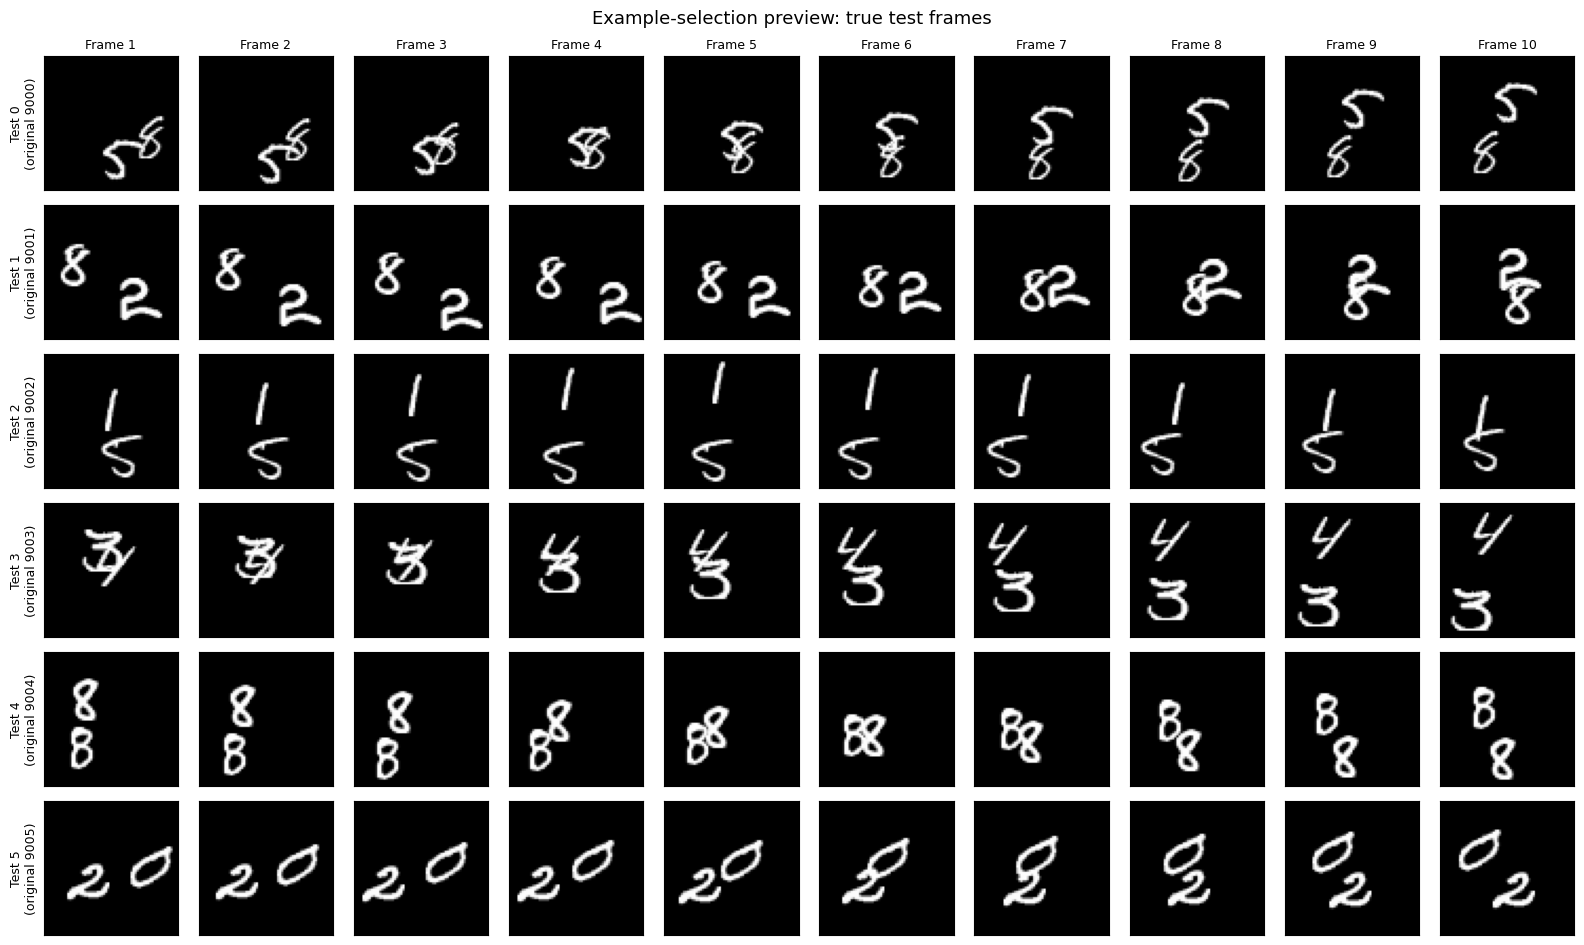

In [22]:
PREVIEW_TEST_IDS = [0, 1, 2, 3, 4, 5]
assert all(0 <= index < len(test_videos) for index in PREVIEW_TEST_IDS)

preview_figure, preview_axes = plt.subplots(
    len(PREVIEW_TEST_IDS), 10,
    figsize=(16, 1.6 * len(PREVIEW_TEST_IDS)),
    squeeze=False,
)
for row, test_index in enumerate(PREVIEW_TEST_IDS):
    true_frames = test_videos[test_index][:10, 0]
    for frame_index in range(10):
        ax = preview_axes[row, frame_index]
        ax.imshow(true_frames[frame_index].numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(f"Frame {frame_index + 1}", fontsize=9)
    preview_axes[row, 0].set_ylabel(
        f"Test {test_index}\n(original {9000 + test_index})",
        fontsize=9,
    )
preview_figure.suptitle("Example-selection preview: true test frames", fontsize=13)
preview_figure.tight_layout()
plt.show()


### 27. Generate Figure 2 from seed 0


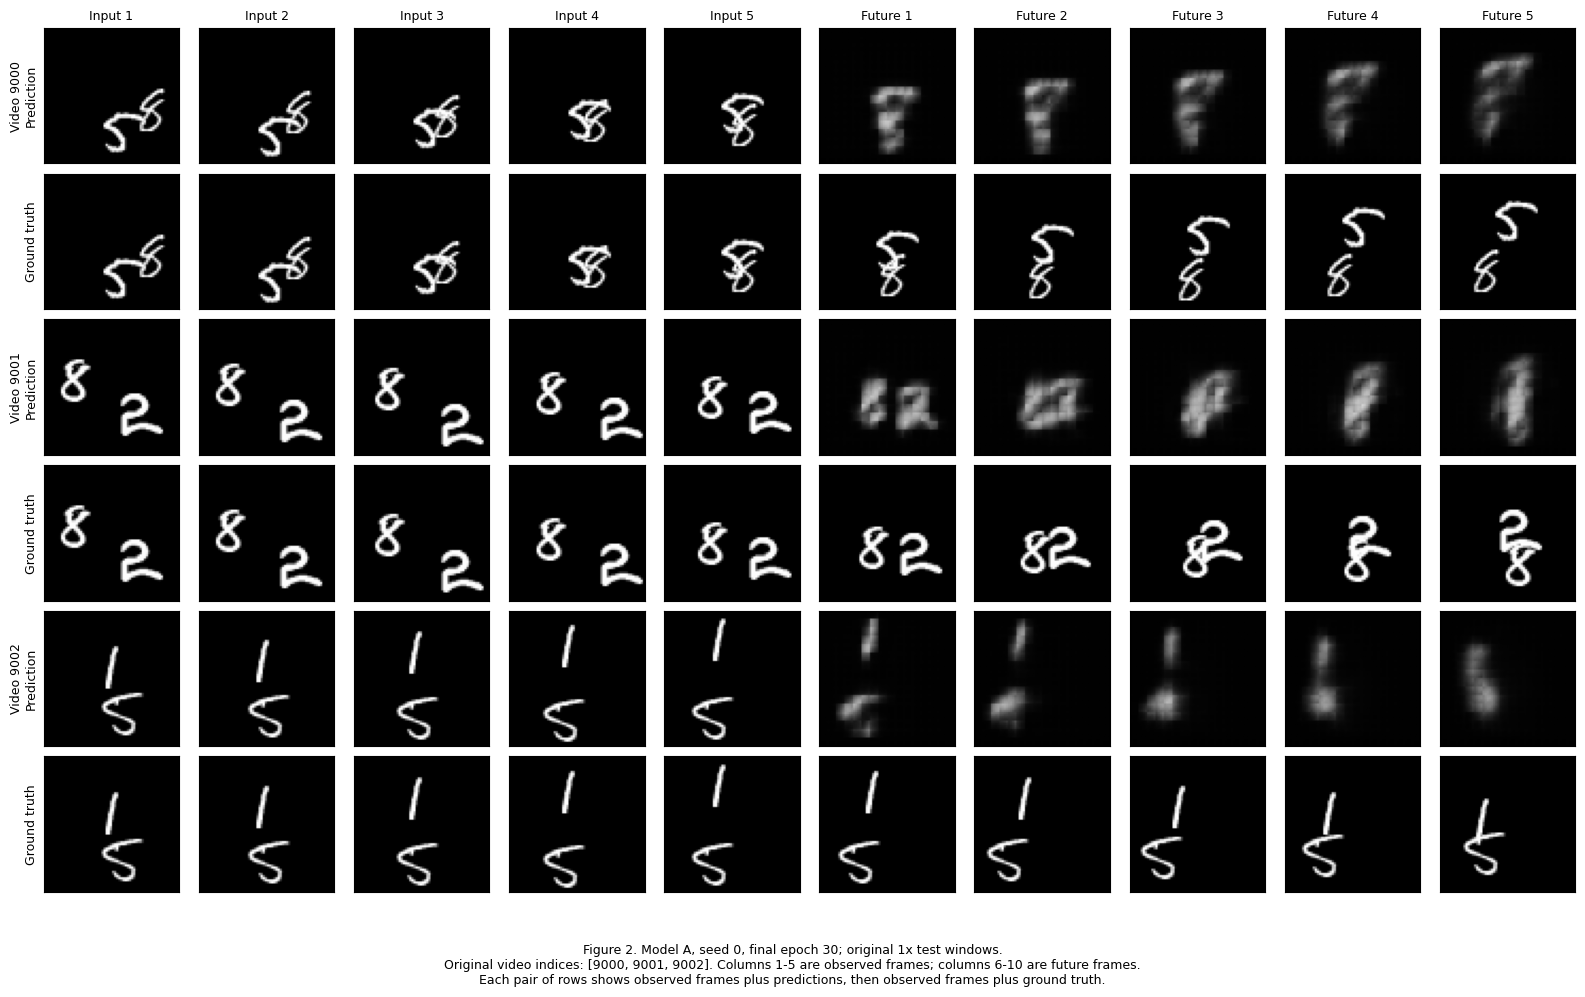

Figure 2 saved to: /content/drive/MyDrive/DL4STG_PA2/outputs/figure2_modelA_examples.png
Confirm visually that a selected example includes overlapping digits.


In [23]:
FIGURE2_TEST_IDS = [0, 1, 2]
assert len(FIGURE2_TEST_IDS) == 3 and len(set(FIGURE2_TEST_IDS)) == 3
assert all(0 <= index < len(test_videos) for index in FIGURE2_TEST_IDS)

seed0_predictions = A_original_results[0]["predictions"]
assert tuple(seed0_predictions.shape) == (1000, 5, 1, 64, 64)
figure2, figure2_axes = plt.subplots(6, 10, figsize=(16, 10), squeeze=False)

for example_number, test_index in enumerate(FIGURE2_TEST_IDS):
    true_frames = test_videos[test_index][:10, 0]
    predicted_frames = seed0_predictions[test_index, :, 0]
    for column in range(10):
        prediction_image = (
            true_frames[column] if column < 5
            else predicted_frames[column - 5]
        )
        for offset, image in [(0, prediction_image), (1, true_frames[column])]:
            row = 2 * example_number + offset
            ax = figure2_axes[row, column]
            ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(
                    f"Input {column + 1}" if column < 5 else f"Future {column - 4}",
                    fontsize=9,
                )
    original_index = 9000 + test_index
    figure2_axes[2 * example_number, 0].set_ylabel(
        f"Video {original_index}\nPrediction", fontsize=9,
    )
    figure2_axes[2 * example_number + 1, 0].set_ylabel(
        "Ground truth", fontsize=9,
    )

figure2_caption = (
    "Figure 2. Model A, seed 0, final epoch 30; original 1x test windows.\\n"
    f"Original video indices: {[9000 + index for index in FIGURE2_TEST_IDS]}. "
    "Columns 1-5 are observed frames; columns 6-10 are future frames.\\n"
    "Each pair of rows shows observed frames plus predictions, "
    "then observed frames plus ground truth."
).replace("\\n", "\n")
figure2.text(0.5, 0.01, figure2_caption, ha="center", va="bottom", fontsize=9)
figure2.tight_layout(rect=(0, 0.09, 1, 1))
figure2_path = OUTPUT_DIR / "figure2_modelA_examples.png"
figure2.savefig(figure2_path, dpi=300, bbox_inches="tight")
(OUTPUT_DIR / "figure2_caption.txt").write_text(figure2_caption, encoding="utf-8")
(OUTPUT_DIR / "figure2_selection.json").write_text(
    json.dumps({
        "test_subset_indices": FIGURE2_TEST_IDS,
        "original_video_indices": [9000 + index for index in FIGURE2_TEST_IDS],
        "seed": 0,
        "start": 1,
        "speed": 1,
    }, indent=2),
    encoding="utf-8",
)
plt.show()
print("Figure 2 saved to:", figure2_path)
print("Confirm visually that a selected example includes overlapping digits.")

### Q2.3 - Model A's reach
Pixel unshuffle changes the image from a 64x64 spatial grid into a 16x16 spatial grid, putting each 4x4 patch into channels.

Therefore, moving one position along the folded grid corresponds to four original pixels.

A 3x3 convolution uses a position and its immediate neighbours; and thus,information can move one folded-grid position horizontally or vertically or diagonally through that convolution.

Model A has two stacked ConvLSTM layers. The current frame enters layer 1, whose new hidden state enters layer 2. Therefore, information can move one position through layer 1, then another position through layer 2. This is essentially 2 of the folded-grid positions along an axis.

Moreover, due to recurrence the layers receive the previous hidden states as well. Considering everything, we have three paths: from current input folded frame to layers 1 through 2, from previous hidden state of layer 1 to layers 1 through 2, and from previous hidden state of layer 2 through layer 2 only.

The longest path contains two 3x3 convolutions, and as discussed these correspond to 4 pixels per position for each convolution. Therefore, we have 8 pixels per time step.

However, do note that as we mentioned above, the information can travel diagonally as well. That yields approximately 11.3 pixels per time step diagonally; the reach along each axis remains 8 pixels.

### Q2.4 - Baseline Performance Discussion
Model A consistently outperforms the two reference predictors, namely Blank and Copy-Last, at 1x speed.

Table 2 shows that model A has a mean E(5) of 0.0224, compared with 0.0426 for Blank and 0.0641 for Copy-Last; and model A has much lower MSE at every forecast horizon compared to the two.

However, its error increases steadily from MSE1 = 0.0170 to MSE5 = 0.0265. Both seeds show this trend, and this is understandable because of error accumulation in the autoregressive nature of predictions. Blank's error remains approximately constant, while Copy-last becomes progressively worse.

When the digits overlap (refer to figure 2) we see blurry blobs rather than distinct and clear digit shapes. Merging and loss of digit identity is observed. But these poor blurry predictions are not necessarily caused due to overlap, as can be seen in video examples without overlapping digits.

### Q2.5 - Predictions before testing the baseline
According to my understanding of Model A, I predict that it will fail both the mirror and rotation tests. Although Figure 1 shows broad coverage of optical flow directions, the architecture does not explicitly enforce consistency under mirroring or rotation. Thus, broad direction coverage alone may not be sufficient for consistent predictions on transformed videos.

For speed transformations, I expect noticeable degradation at 2x and the clearest breakdown at 3x. Typical training speeds are around 3-4 pixels/frame, whereas the scaled median references are approximately 6.64 and 9.95 pixels/frame. The 2x reference is within the model's eight-pixel reach along each axis, but these larger displacements are less familiar from training. At 3x, near-axis-aligned movement can exceed that reach, although some diagonal movements remain within the spatial support. Therefore, unfamiliar speeds and limited reach may both contribute to increased blur, misplaced predictions and loss of digit identity

## Stage 7: Testing the baseline

**Goal:** generate Tables 3-4 and Figures 3-5, including the four Figure 3 GIFs, using the final model A checkpoints.


### 28. Restore the saved baseline results

Load the original 1x predictions and full-precision Table 2 metrics from Drive. The cache checks verify video order, seed, task settings, shape, and agreement with the saved baseline error.

The first transformed evaluation also checks a fresh original batch against its saved predictions. If that comparison fails, refresh Step 25's caches using the same final checkpoints; do not retrain.


In [10]:
import pandas as pd
import cv2
import zipfile
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

PRETEST_COMMIT = "31adeaa74eaec058ac1a8b2f945f9e2c0c178ea8"
baseline_metrics = json.loads(
    (OUTPUT_DIR / "table2_metrics.json").read_text(encoding="utf-8")
)
A_original_results = {}
for seed in (0, 1):
    cache = torch.load(
        OUTPUT_DIR / f"baseline_A_seed{seed}_original_1x.pt",
        map_location="cpu",
        weights_only=True,
    )
    assert cache["seed"] == seed and cache["start"] == cache["speed"] == 1
    assert torch.equal(
        cache["original_video_indices"], torch.arange(9000, 10000)
    )
    assert tuple(cache["predictions"].shape) == (1000, 5, 1, 64, 64)
    assert tuple(cache["per_video_mse"].shape) == (1000, 5)
    metadata = baseline_metrics["model_A"][str(seed)]
    assert np.isclose(
        cache["per_video_mse"].double().mean().item(),
        metadata["E5"], rtol=1e-7, atol=1e-10,
    )
    A_original_results[seed] = {
        **metadata,
        "predictions": cache["predictions"],
        "per_video_mse": cache["per_video_mse"],
    }


def format_error(value):
    return f"{value:.2e}" if abs(value) < 1e-3 else f"{value:#.3g}"


def format_seed_error(value0, value1):
    mean = (value0 + value1) / 2
    return f"{format_error(mean)} ({format_error(value0)}, {format_error(value1)})"


SYMMETRIES = {"M": mirror, "R": rotate}
GIF_DIR = OUTPUT_DIR / "gifs"
GIF_DIR.mkdir(parents=True, exist_ok=True)
print("Original predictions restored for both seeds.")
print("Evaluation device:", EVAL_DEVICE)
print("Q2.5 pre-test commit:", PRETEST_COMMIT)

Original predictions restored for both seeds.
Evaluation device: cuda
Q2.5 pre-test commit: 31adeaa74eaec058ac1a8b2f945f9e2c0c178ea8


### 29. Define the stress-test measurements

For mirror and rotation, compute two distinct errors per video:

- **C:** MSE between f(T(X)) and T(f(X)), measuring consistency.
- **E:** MSE between f(T(X)) and T(Y), measuring correctness.

Both average over all five horizons and all pixels before averaging over the 1,000 videos.

For speeds 1x, 2x, and 3x, the model always generates five forecasts. Score only the available targets: five at 1x/2x and two at 3x. All cross-speed comparisons use E(2), the first two horizons. E(5) is recorded only where five targets exist.

Seed-0 transformed predictions are retained for Figure 3. Speed-test caches retain only the first two predictions needed for Figure 5, after the model has generated all five.

In [11]:
class StressTestWindows(Dataset):
    def __init__(self, base_videos, speed=1):
        self.base_videos = base_videos
        self.speed = speed

    def __len__(self):
        return len(self.base_videos)

    def __getitem__(self, index):
        return make_window(self.base_videos[index], start=1, speed=self.speed)


def stress_loader(speed=1):
    return DataLoader(
        StressTestWindows(test_videos, speed),
        batch_size=32, shuffle=False, num_workers=0,
        pin_memory=EVAL_DEVICE.type == "cuda",
    )


def evaluate_symmetry(predictor, transform, original_predictions=None,
                      keep_predictions=False):
    predictor = predictor.to(EVAL_DEVICE).eval()
    c_batches, e_batches, predicted_batches = [], [], []
    offset = 0
    with torch.no_grad():
        for inputs, targets, mask in stress_loader(1):
            inputs = inputs.to(EVAL_DEVICE, non_blocking=True)
            targets = targets.to(EVAL_DEVICE, non_blocking=True)
            assert mask.all()
            batch_size = inputs.shape[0]

            if original_predictions is None:
                original = predictor(inputs)
            else:
                original = original_predictions[offset:offset + batch_size].to(
                    EVAL_DEVICE
                )
                if offset == 0:
                    torch.testing.assert_close(
                        predictor(inputs), original, rtol=1e-4, atol=1e-4,
                        msg="Original cache mismatch: rerun Step 25 with the saved final weights.",
                    )

            transformed_prediction = predictor(transform(inputs))
            transformed_original = transform(original)
            transformed_target = transform(targets)
            c_values = (transformed_prediction - transformed_original).square().mean(
                dim=(1, 2, 3, 4)
            )
            e_values = (transformed_prediction - transformed_target).square().mean(
                dim=(1, 2, 3, 4)
            )
            assert torch.isfinite(c_values).all() and torch.isfinite(e_values).all()
            c_batches.append(c_values.cpu())
            e_batches.append(e_values.cpu())
            if keep_predictions:
                predicted_batches.append(transformed_prediction.cpu())
            offset += batch_size

    assert offset == 1000
    per_video_c = torch.cat(c_batches)
    per_video_e = torch.cat(e_batches)
    return {
        "C": per_video_c.double().mean().item(),
        "E": per_video_e.double().mean().item(),
        "per_video_C": per_video_c,
        "per_video_E": per_video_e,
        "predictions": (
            torch.cat(predicted_batches) if keep_predictions else None
        ),
    }


def evaluate_speed(predictor, speed, keep_predictions=False):
    predictor = predictor.to(EVAL_DEVICE).eval()
    e2_batches, e5_batches, predicted_batches = [], [], []
    valid_horizons = 2 if speed == 3 else 5
    with torch.no_grad():
        for inputs, targets, mask in stress_loader(speed):
            assert mask[:, :valid_horizons].all()
            assert not mask[:, valid_horizons:].any()
            inputs = inputs.to(EVAL_DEVICE, non_blocking=True)
            targets = targets.to(EVAL_DEVICE, non_blocking=True)
            predictions = predictor(inputs)
            assert predictions.shape[1] == 5
            assert torch.isfinite(predictions).all()

            # Unavailable targets are excluded before any error is calculated.
            errors = (
                predictions[:, :valid_horizons] - targets[:, :valid_horizons]
            ).square().mean(dim=(2, 3, 4))
            e2_batches.append(errors[:, :2].mean(dim=1).cpu())
            if valid_horizons == 5:
                e5_batches.append(errors.mean(dim=1).cpu())
            if keep_predictions:
                predicted_batches.append(predictions[:, :2].cpu())

    per_video_e2 = torch.cat(e2_batches)
    assert tuple(per_video_e2.shape) == (1000,)
    per_video_e5 = torch.cat(e5_batches) if e5_batches else None
    return {
        "E2": per_video_e2.double().mean().item(),
        "E5": (
            per_video_e5.double().mean().item()
            if per_video_e5 is not None else None
        ),
        "per_video_E2": per_video_e2,
        "per_video_E5": per_video_e5,
        "predictions": (
            torch.cat(predicted_batches) if keep_predictions else None
        ),
    }


def top_two_ids(gaps):
    return np.argsort(-np.asarray(gaps), kind="stable")[:2].tolist()


print("Stress-test measurement functions defined.")

Stress-test measurement functions defined.


### 30. Run mirror/rotation tests and generate Table 3

For each learned seed, load its final-epoch model and compare against that seed's original predictions. Blank and Copy-last are evaluated directly, including their consistency gaps; their gaps must be exactly zero.

Each learned metric is displayed as mean (seed 0, seed 1). Deterministic reference predictors have one value.

In [12]:
symmetry_results = {}
for seed in (0, 1):
    model = load_final_model_a(seed)
    symmetry_results[seed] = {}
    for name, transform in SYMMETRIES.items():
        result = evaluate_symmetry(
            model, transform,
            original_predictions=A_original_results[seed]["predictions"],
            keep_predictions=seed == 0,
        )
        symmetry_results[seed][name] = result
        print(
            f"A seed {seed}, {name}: C={format_error(result['C'])}, "
            f"E={format_error(result['E'])}"
        )
    del model

symmetry_references = {}
for label, predictor in [
    ("Blank", BlankPredictor()), ("Copy-last", CopyLastPredictor())
]:
    symmetry_references[label] = {}
    for name, transform in SYMMETRIES.items():
        result = evaluate_symmetry(predictor, transform)
        assert torch.count_nonzero(result["per_video_C"]).item() == 0
        assert np.isclose(
            result["E"], baseline_metrics["references"][label]["E5"],
            rtol=1e-6, atol=1e-9,
        )
        symmetry_references[label][name] = result

row = {
    "Model": "A",
    "E(5)": format_seed_error(
        A_original_results[0]["E5"], A_original_results[1]["E5"]
    ),
}
for name in ("M", "R"):
    for metric in ("C", "E"):
        row[f"{metric}_{name}"] = format_seed_error(
            symmetry_results[0][name][metric],
            symmetry_results[1][name][metric],
        )
table3_rows = [row]
for label in ("Blank", "Copy-last"):
    row = {
        "Model": label,
        "E(5)": format_error(baseline_metrics["references"][label]["E5"]),
    }
    for name in ("M", "R"):
        for metric in ("C", "E"):
            row[f"{metric}_{name}"] = format_error(
                symmetry_references[label][name][metric]
            )
    table3_rows.append(row)

table3 = pd.DataFrame(table3_rows)
display(table3)
table3.to_csv(OUTPUT_DIR / "table3.csv", index=False)
print("Table 3 saved. Both deterministic consistency checks passed.")

A seed 0, M: C=0.00165, E=0.0234
A seed 0, R: C=0.00283, E=0.0244
A seed 1, M: C=0.00168, E=0.0226
A seed 1, R: C=0.00289, E=0.0234


,Model,E(5),C_M,E_M,C_R,E_R
0,A,"0.0224 (0.0228, 0.0219)","0.00166 (0.00165, 0.00168)","0.0230 (0.0234, 0.0226)","0.00286 (0.00283, 0.00289)","0.0239 (0.0244, 0.0234)"
1,Blank,0.0426,0.00e+00,0.0426,0.00e+00,0.0426
2,Copy-last,0.0641,0.00e+00,0.0641,0.00e+00,0.0641


Table 3 saved. Both deterministic consistency checks passed.


### 31. Generate Figure 3 and its four GIFs

Select the two largest per-video C_M values and the two largest per-video C_R values from seed 0. Selection is independent for each transformation: if the same video appears in both lists, it appears twice.

Each PNG has the exact four rows and ten columns specified in the handout. Each GIF keeps the four rows and five observed input frames fixed while its last column advances through forecast horizons 1-5.

Captions give repository-relative GIF paths under outputs/gifs. The final archive preserves those paths when extracted into the repository.

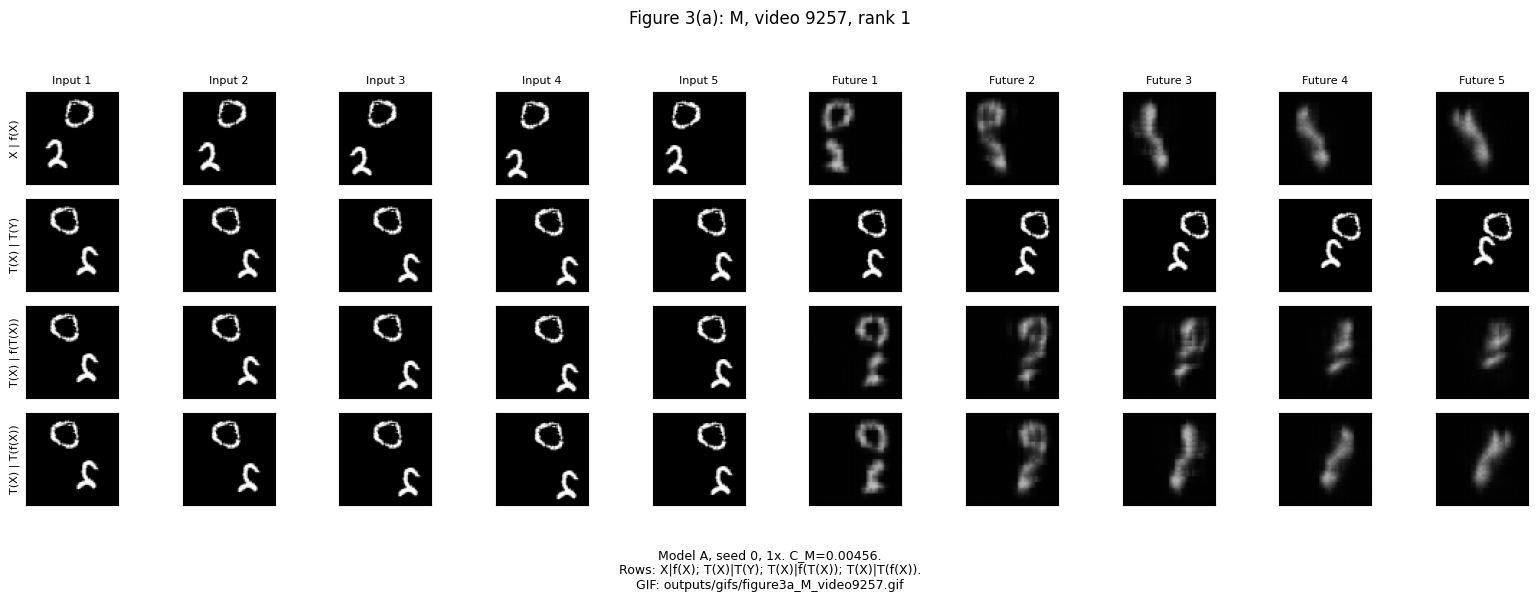

outputs/gifs/figure3a_M_video9257.gif


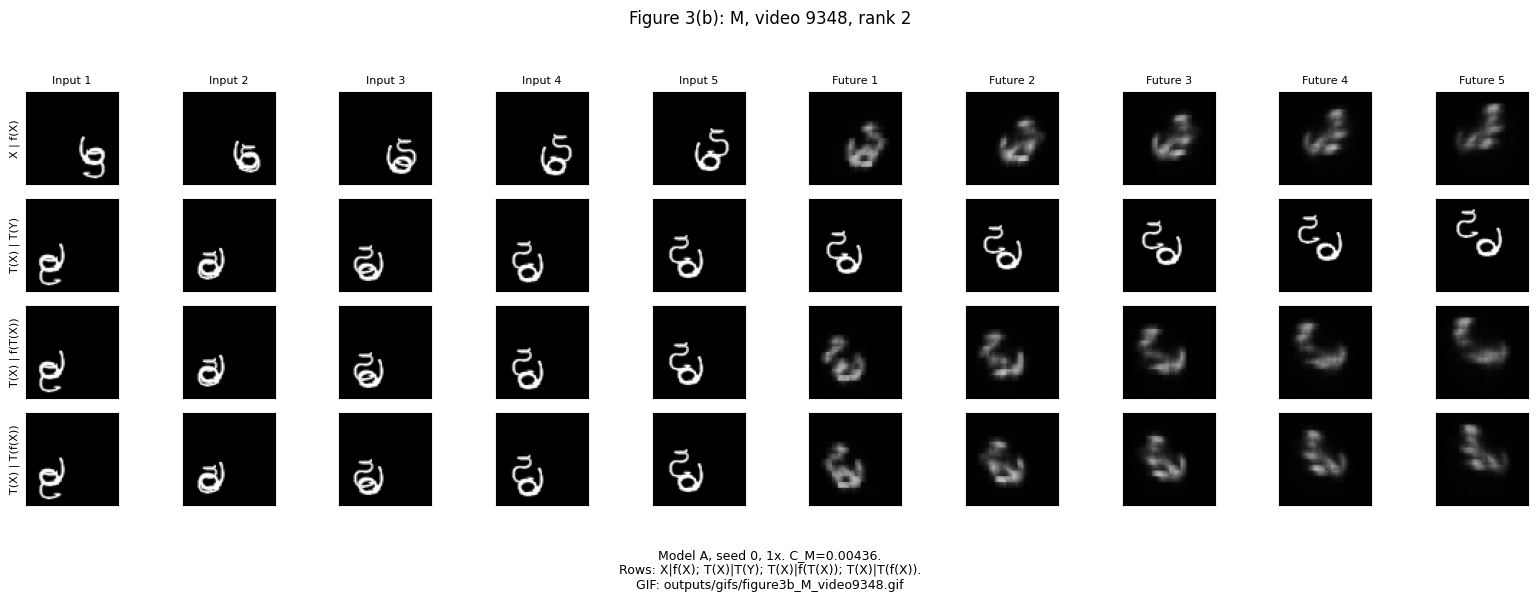

outputs/gifs/figure3b_M_video9348.gif


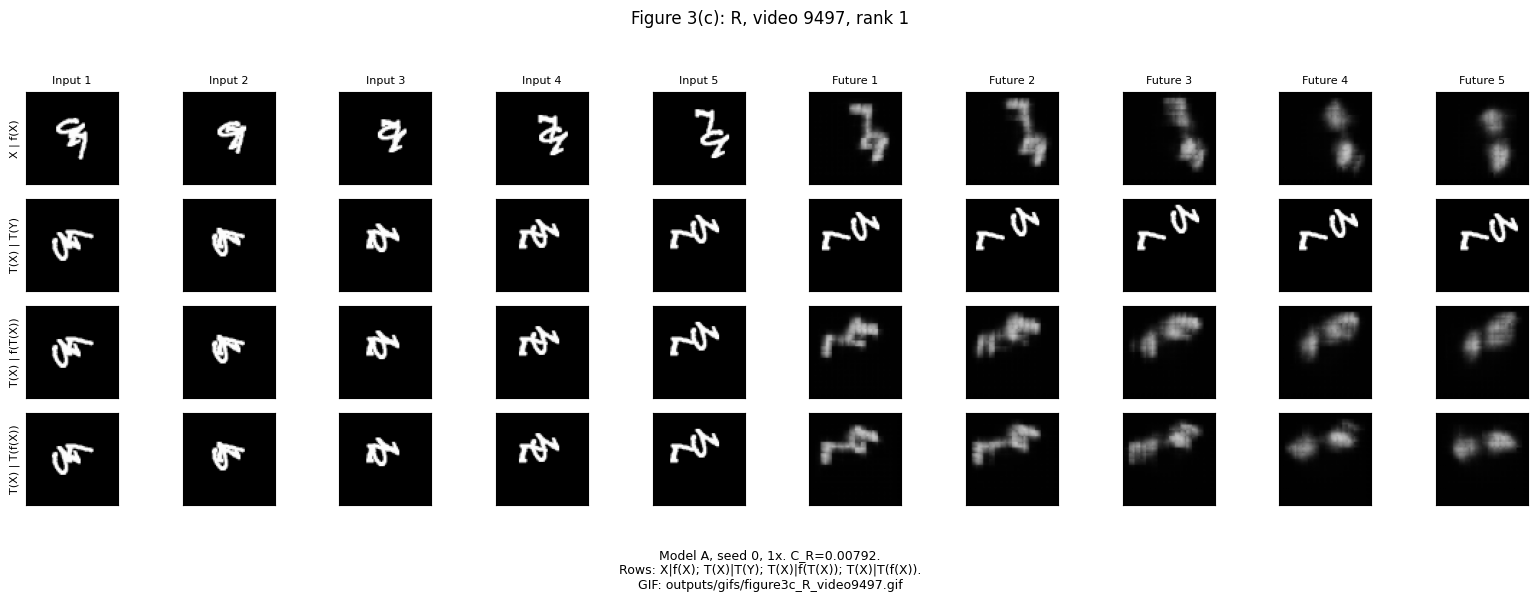

outputs/gifs/figure3c_R_video9497.gif


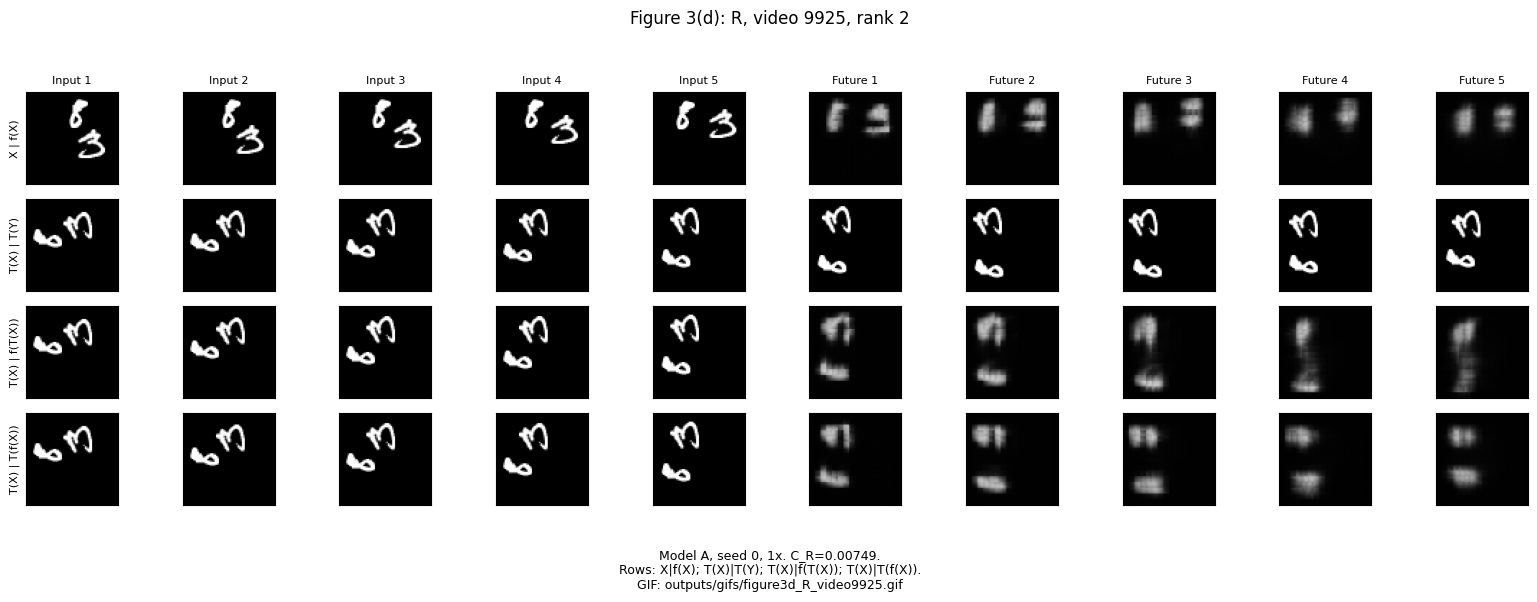

outputs/gifs/figure3d_R_video9925.gif


,panel,transform,rank,test_index,original_video_index,consistency_gap,gif_path
0,a,M,1,257,9257,0.004555,outputs/gifs/figure3a_M_video9257.gif
1,b,M,2,348,9348,0.004362,outputs/gifs/figure3b_M_video9348.gif
2,c,R,1,497,9497,0.007923,outputs/gifs/figure3c_R_video9497.gif
3,d,R,2,925,9925,0.007489,outputs/gifs/figure3d_R_video9925.gif


In [13]:
PANEL_ROW_LABELS = [
    "X | f(X)", "T(X) | T(Y)", "T(X) | f(T(X))", "T(X) | T(f(X))"
]


def save_panel_gif(panel, title, path):
    """Animate five future horizons while keeping four rows and input context."""
    assert panel.shape == (4, 10, 64, 64)
    size, gap, label_width, header_height = 128, 4, 190, 58
    font = ImageFont.load_default(size=16)
    frames = []
    for horizon in range(5):
        canvas = Image.new(
            "RGB",
            (label_width + 6 * (size + gap), header_height + 4 * (size + gap)),
            "white",
        )
        draw = ImageDraw.Draw(canvas)
        draw.text((8, 5), f"{title} | horizon {horizon + 1}", fill="black", font=font)
        for column in range(6):
            label = f"Input {column + 1}" if column < 5 else f"Future {horizon + 1}"
            draw.text(
                (label_width + column * (size + gap), 32),
                label, fill="black", font=font,
            )
        for row in range(4):
            draw.text(
                (6, header_height + row * (size + gap) + 48),
                PANEL_ROW_LABELS[row], fill="black", font=font,
            )
            for column, frame_index in enumerate([0, 1, 2, 3, 4, 5 + horizon]):
                pixels = np.rint(np.clip(panel[row, frame_index], 0, 1) * 255).astype(
                    np.uint8
                )
                tile = Image.fromarray(pixels).resize(
                    (size, size), Image.Resampling.NEAREST
                ).convert("RGB")
                canvas.paste(
                    tile,
                    (label_width + column * (size + gap),
                     header_height + row * (size + gap)),
                )
        frames.append(canvas)
    frames[0].save(
        path, save_all=True, append_images=frames[1:],
        duration=600, loop=0, disposal=2, optimize=False,
    )


figure3_cases = []
for name in ("M", "R"):
    ids = top_two_ids(symmetry_results[0][name]["per_video_C"].numpy())
    for rank, test_index in enumerate(ids, start=1):
        letter = "abcd"[len(figure3_cases)]
        original_index = 9000 + test_index
        gap = symmetry_results[0][name]["per_video_C"][test_index].item()
        stem = f"figure3{letter}_{name}_video{original_index}"
        gif_relative = f"outputs/gifs/{stem}.gif"
        case = {
            "panel": letter, "transform": name, "rank": rank,
            "test_index": test_index, "original_video_index": original_index,
            "consistency_gap": gap, "gif_path": gif_relative,
        }
        figure3_cases.append(case)

        inputs, targets, _ = make_window(test_videos[test_index], start=1, speed=1)
        original = A_original_results[0]["predictions"][test_index]
        transformed_prediction = symmetry_results[0][name]["predictions"][test_index]
        transform = SYMMETRIES[name]
        transformed_inputs = transform(inputs)
        panel = torch.stack([
            torch.cat([inputs, original]),
            torch.cat([transformed_inputs, transform(targets)]),
            torch.cat([transformed_inputs, transformed_prediction]),
            torch.cat([transformed_inputs, transform(original)]),
        ])[:, :, 0].numpy()

        title = f"Figure 3({letter}): {name}, video {original_index}, rank {rank}"
        caption = (
            f"Model A, seed 0, 1x. C_{name}={format_error(gap)}.\n"
            "Rows: X|f(X); T(X)|T(Y); T(X)|f(T(X)); T(X)|T(f(X)).\n"
            f"GIF: {gif_relative}"
        )
        fig, axes = plt.subplots(4, 10, figsize=(16, 6), squeeze=False)
        for row in range(4):
            for column in range(10):
                ax = axes[row, column]
                ax.imshow(panel[row, column], cmap="gray", vmin=0, vmax=1)
                ax.set_xticks([])
                ax.set_yticks([])
                if row == 0:
                    ax.set_title(
                        f"Input {column + 1}" if column < 5 else f"Future {column - 4}",
                        fontsize=8,
                    )
            axes[row, 0].set_ylabel(PANEL_ROW_LABELS[row], fontsize=8)
        fig.suptitle(title)
        fig.text(0.5, 0.01, caption, ha="center", va="bottom", fontsize=9)
        fig.tight_layout(rect=(0, 0.13, 1, 0.95))
        fig.savefig(OUTPUT_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
        (OUTPUT_DIR / f"{stem}_caption.txt").write_text(caption, encoding="utf-8")
        save_panel_gif(panel, title, GIF_DIR / f"{stem}.gif")
        plt.show()
        print(gif_relative)

display(pd.DataFrame(figure3_cases))

### 32. Generate Figure 4: per-video consistency distributions

Plot all 1,000 seed-0 gaps for each transformation, and mark the two selected Figure 3 examples in the corresponding histogram. The vertical axis counts test videos.

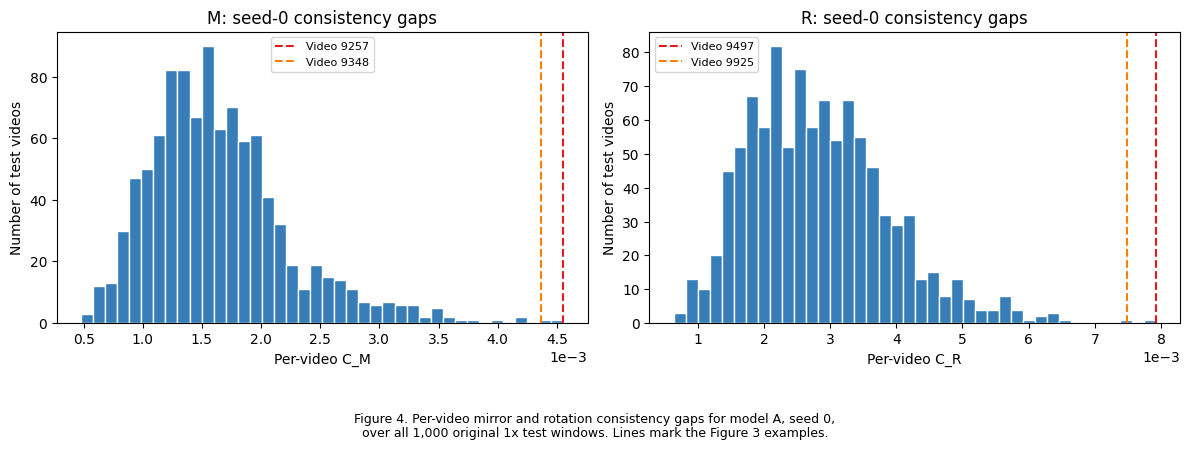

In [14]:
fig4, axes4 = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes4, ("M", "R")):
    gaps = symmetry_results[0][name]["per_video_C"].numpy()
    ax.hist(gaps, bins=40, color="#377eb8", edgecolor="white")
    selected = [case for case in figure3_cases if case["transform"] == name]
    for color, case in zip(("#e41a1c", "#ff7f00"), selected):
        ax.axvline(
            case["consistency_gap"], color=color, linestyle="--",
            label=f"Video {case['original_video_index']}",
        )
    ax.set(title=f"{name}: seed-0 consistency gaps",
           xlabel=f"Per-video C_{name}", ylabel="Number of test videos")
    ax.ticklabel_format(axis="x", style="sci", scilimits=(-3, 3))
    ax.legend(fontsize=8)
caption4 = (
    "Figure 4. Per-video mirror and rotation consistency gaps for model A, seed 0,\n"
    "over all 1,000 original 1x test windows. Lines mark the Figure 3 examples."
)
fig4.text(0.5, 0.01, caption4, ha="center", va="bottom", fontsize=9)
fig4.tight_layout(rect=(0, 0.14, 1, 1))
fig4.savefig(OUTPUT_DIR / "figure4_consistency_histograms.png", dpi=300, bbox_inches="tight")
(OUTPUT_DIR / "figure4_caption.txt").write_text(caption4, encoding="utf-8")
plt.show()

### 33. Run the speed tests and generate Table 4

Reuse model A's original 1x results, then evaluate 2x and 3x for both seeds. Copy-last is evaluated at all three speeds.

E(2) uses exactly two horizons at every speed. Table 4 contains E(5) only at 1x and 2x; unavailable 3x targets never contribute to a metric.

In [15]:
speed_results = {}
for seed in (0, 1):
    original = A_original_results[seed]
    original_horizon_errors = original["per_video_mse"]
    speed_results[seed] = {
        1: {
            "E2": original["E2"], "E5": original["E5"],
            "per_video_E2": original_horizon_errors[:, :2].mean(dim=1),
            "per_video_E5": original_horizon_errors.mean(dim=1),
            "predictions": original["predictions"][:, :2] if seed == 0 else None,
        }
    }
    model = load_final_model_a(seed)
    for speed in (2, 3):
        result = evaluate_speed(model, speed, keep_predictions=seed == 0)
        speed_results[seed][speed] = result
        print(f"A seed {seed}, {speed}x: E(2)={format_error(result['E2'])}")
    del model

speed_copy = {
    speed: evaluate_speed(CopyLastPredictor(), speed) for speed in (1, 2, 3)
}
table4_rows = []
for model_name in ("A", "Copy-last"):
    row = {"Model": model_name}
    for metric, speeds in [("E2", (1, 2, 3)), ("E5", (1, 2))]:
        for speed in speeds:
            label = f"E({metric[-1]}) at {speed}x"
            row[label] = (
                format_seed_error(
                    speed_results[0][speed][metric], speed_results[1][speed][metric]
                )
                if model_name == "A"
                else format_error(speed_copy[speed][metric])
            )
    table4_rows.append(row)
table4 = pd.DataFrame(table4_rows)
display(table4)
table4.to_csv(OUTPUT_DIR / "table4.csv", index=False)
print("Table 4 saved.")

A seed 0, 2x: E(2)=0.0436
A seed 0, 3x: E(2)=0.0499
A seed 1, 2x: E(2)=0.0451
A seed 1, 3x: E(2)=0.0506


,Model,E(2) at 1x,E(2) at 2x,E(2) at 3x,E(5) at 1x,E(5) at 2x
0,A,"0.0189 (0.0195, 0.0182)","0.0443 (0.0436, 0.0451)","0.0503 (0.0499, 0.0506)","0.0224 (0.0228, 0.0219)","0.0482 (0.0475, 0.0489)"
1,Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719


Table 4 saved.


### 34. Preview possible non-overlapping examples for Figure 5

Figure 5 requires a video with no overlapping digits in **any displayed true frame**, including the later 2x/3x targets.

The union of displayed true frames is 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 13, 16, 19. The screen below suggests up to three videos with two sufficiently large foreground components in every one of those frames. This is a heuristic, not a ground-truth overlap label.

Inspect the preview and confirm that both digits remain separate in all displayed frames. Set FIGURE5_TEST_ID in the next cell to a suitable example. If a suggestion is unsuitable, choose another candidate or extend the preview.

Suggested test-subset indices: [21, 26, 29]
Confirm separation visually; the screen is only a suggestion.


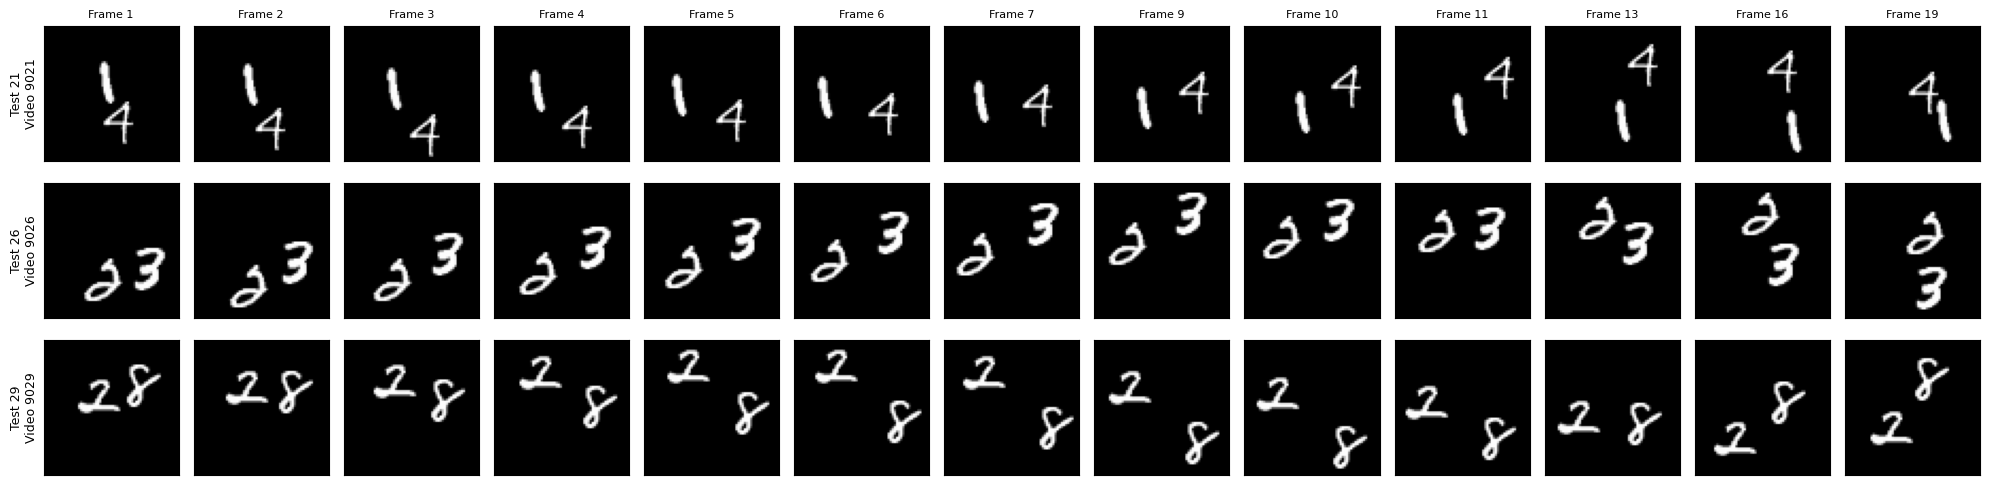

In [16]:
DISPLAYED_TRUE_FRAMES = sorted({
    frame
    for speed in (1, 2, 3)
    for frames in [
        window_frame_numbers(1, speed)[0],
        window_frame_numbers(1, speed)[1][:2],
    ]
    for frame in frames
})
assert DISPLAYED_TRUE_FRAMES == [1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 13, 16, 19]


def separate_component_screen(frames):
    for frame in frames:
        foreground = np.ascontiguousarray((frame > 0.2).astype(np.uint8))
        _, _, statistics, _ = cv2.connectedComponentsWithStats(
            foreground, connectivity=8
        )
        if np.count_nonzero(statistics[1:, cv2.CC_STAT_AREA] >= 10) != 2:
            return False
    return True


SPEED_CANDIDATES = []
for test_index in range(len(test_videos)):
    frames = test_videos[test_index][
        [frame - 1 for frame in DISPLAYED_TRUE_FRAMES], 0
    ].numpy()
    if separate_component_screen(frames):
        SPEED_CANDIDATES.append(test_index)
    if len(SPEED_CANDIDATES) == 3:
        break

preview_ids = SPEED_CANDIDATES or [0, 1, 2]
print("Suggested test-subset indices:", SPEED_CANDIDATES)
print("Confirm separation visually; the screen is only a suggestion.")
preview, axes = plt.subplots(
    len(preview_ids), len(DISPLAYED_TRUE_FRAMES),
    figsize=(20, 1.7 * len(preview_ids)), squeeze=False,
)
for row, test_index in enumerate(preview_ids):
    video = test_videos[test_index]
    for column, frame in enumerate(DISPLAYED_TRUE_FRAMES):
        ax = axes[row, column]
        ax.imshow(video[frame - 1, 0].numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(f"Frame {frame}", fontsize=8)
    axes[row, 0].set_ylabel(f"Test {test_index}\nVideo {9000 + test_index}", fontsize=9)
preview.tight_layout()
plt.show()

### 35. Generate Figure 5 and save the example selections

The default uses the first screened candidate. Change FIGURE5_TEST_ID after reviewing the preview if needed.

For each speed, show five inputs and two future frames. The prediction row and true-future row share the same observed frames. Labels give the actual original-video frame numbers.

The saved selection file fixes the Figure 3 and Figure 5 examples for the final model's Figure 6 later. Verify the non-overlap requirement now, before accepting this selection.

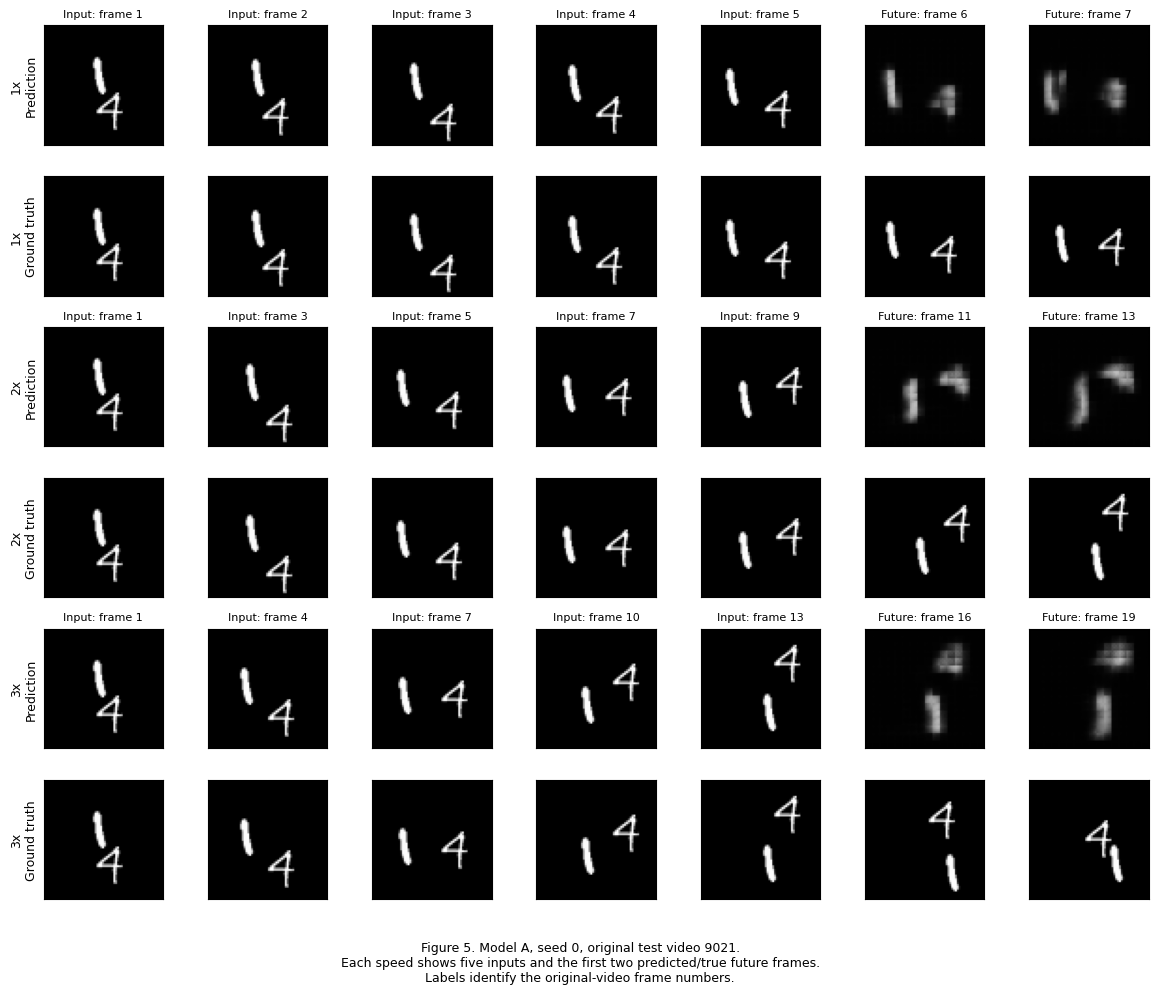

Figure 5 and selections saved. Confirm no overlap in its displayed true frames.


In [17]:
FIGURE5_TEST_ID = SPEED_CANDIDATES[0] if SPEED_CANDIDATES else 0
assert 0 <= FIGURE5_TEST_ID < 1000
figure5, axes5 = plt.subplots(6, 7, figsize=(12, 10), squeeze=False)
for speed in (1, 2, 3):
    inputs, targets, _ = make_window(
        test_videos[FIGURE5_TEST_ID], start=1, speed=speed
    )
    predictions = speed_results[0][speed]["predictions"][FIGURE5_TEST_ID]
    prediction_row = torch.cat([inputs, predictions])
    truth_row = torch.cat([inputs, targets[:2]])
    input_frames, target_frames = window_frame_numbers(1, speed)
    numbers = input_frames + target_frames[:2]
    for offset, frames in [(0, prediction_row), (1, truth_row)]:
        row = 2 * (speed - 1) + offset
        for column in range(7):
            ax = axes5[row, column]
            ax.imshow(frames[column, 0].numpy(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if offset == 0:
                kind = "Input" if column < 5 else "Future"
                ax.set_title(f"{kind}: frame {numbers[column]}", fontsize=8)
        axes5[row, 0].set_ylabel(
            f"{speed}x\n" + ("Prediction" if offset == 0 else "Ground truth"),
            fontsize=9,
        )

caption5 = (
    f"Figure 5. Model A, seed 0, original test video {9000 + FIGURE5_TEST_ID}.\n"
    "Each speed shows five inputs and the first two predicted/true future frames.\n"
    "Labels identify the original-video frame numbers."
)
figure5.text(0.5, 0.01, caption5, ha="center", va="bottom", fontsize=9)
figure5.tight_layout(rect=(0, 0.08, 1, 1))
figure5.savefig(OUTPUT_DIR / "figure5_speed_examples.png", dpi=300, bbox_inches="tight")
(OUTPUT_DIR / "figure5_caption.txt").write_text(caption5, encoding="utf-8")
plt.show()

baseline_selections = {
    "pretest_commit": PRETEST_COMMIT,
    "figure3_cases": figure3_cases,
    "figure5_test_index": FIGURE5_TEST_ID,
    "figure5_original_video_index": 9000 + FIGURE5_TEST_ID,
    "figure5_displayed_true_frames": DISPLAYED_TRUE_FRAMES,
    "figure5_overlap_confirmation": "Awaiting visual review of displayed frames.",
}
(OUTPUT_DIR / "baseline_example_selections.json").write_text(
    json.dumps(baseline_selections, indent=2), encoding="utf-8"
)
print("Figure 5 and selections saved. Confirm no overlap in its displayed true frames.")

### 36. Save metrics and package report artifacts

Save full-precision summary metrics and a per-video CSV. The archive includes tables, captions, selection metadata, figures, and the four Figure 3 GIFs. It excludes datasets, model checkpoints, and large prediction caches.

The archive contains an outputs/ folder. When extracted into the repository, the GIF paths in Figure 3's captions will point to the correct files.

After review, download the archive from Drive (or use the optional download line) and share it with the executed notebook so the report artifacts can be committed.

In [18]:
symmetry_summary = {
    "pretest_commit": PRETEST_COMMIT,
    "environment": {**environment, "opencv": cv2.__version__},
    "model_A": {
        str(seed): {
            name: {metric: symmetry_results[seed][name][metric] for metric in ("C", "E")}
            for name in ("M", "R")
        } for seed in (0, 1)
    },
    "references": {
        label: {
            name: {metric: symmetry_references[label][name][metric] for metric in ("C", "E")}
            for name in ("M", "R")
        } for label in ("Blank", "Copy-last")
    },
}
speed_summary = {
    "model_A": {
        str(seed): {
            str(speed): {metric: speed_results[seed][speed][metric] for metric in ("E2", "E5")}
            for speed in (1, 2, 3)
        } for seed in (0, 1)
    },
    "Copy-last": {
        str(speed): {metric: speed_copy[speed][metric] for metric in ("E2", "E5")}
        for speed in (1, 2, 3)
    },
}
(OUTPUT_DIR / "table3_metrics.json").write_text(
    json.dumps(symmetry_summary, indent=2), encoding="utf-8"
)
(OUTPUT_DIR / "table4_metrics.json").write_text(
    json.dumps(speed_summary, indent=2), encoding="utf-8"
)

per_video = {"original_video_index": np.arange(9000, 10000)}
for seed in (0, 1):
    for name in ("M", "R"):
        for metric in ("C", "E"):
            per_video[f"{metric}_{name}_seed{seed}"] = (
                symmetry_results[seed][name][f"per_video_{metric}"].numpy()
            )
    for speed in (1, 2, 3):
        per_video[f"E2_{speed}x_seed{seed}"] = (
            speed_results[seed][speed]["per_video_E2"].numpy()
        )
pd.DataFrame(per_video).to_csv(
    OUTPUT_DIR / "baseline_stress_per_video.csv", index=False
)

artifact_paths = []
for pattern in (
    "table[1-4].csv", "table[234]_metrics.json",
    "figure[1245]*.png", "figure[1245]*.txt", "figure[25]*.json",
    "baseline_example_selections.json", "baseline_stress_per_video.csv",
):
    artifact_paths.extend(OUTPUT_DIR.glob(pattern))
for case in figure3_cases:
    stem = Path(case["gif_path"]).stem
    artifact_paths.extend([
        OUTPUT_DIR / f"{stem}.png",
        OUTPUT_DIR / f"{stem}_caption.txt",
        PROJECT_DIR / case["gif_path"],
    ])
assert all(path.is_file() for path in artifact_paths)
artifact_paths = sorted(set(artifact_paths))
assert len([path for path in artifact_paths if path.suffix == ".gif"]) == 4

artifact_zip = PROJECT_DIR / "baseline_stress_results.zip"
with zipfile.ZipFile(artifact_zip, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in artifact_paths:
        archive.write(path, arcname=path.relative_to(PROJECT_DIR).as_posix())

print("Saved Tables 3-4, Figures 3-5, four GIFs, metrics, and example selections.")
print("Report artifact archive:", artifact_zip)
print("Archive size:", f"{artifact_zip.stat().st_size / (1024 ** 2):.2f} MiB")
print("Review the figures and confirm Figure 5 has no overlap before drafting Q2.6-Q2.10.")

Saved Tables 3-4, Figures 3-5, four GIFs, metrics, and example selections.
Report artifact archive: /content/drive/MyDrive/DL4STG_PA2/baseline_stress_results.zip
Archive size: 2.41 MiB
Review the figures and confirm Figure 5 has no overlap before drafting Q2.6-Q2.10.


In [19]:
# Optional: uncomment to download the archive directly from Colab.
# from google.colab import files
# files.download(str(artifact_zip))

### Q2.6 — Consistency Gap and Error

Reading and evaluating on the basis of consistency gap alone is problematic because transformation equivariance does not guarantee accurate forecasts. Blank and Copy-last both have \(C_T=0\), yet their transformed errors are 0.0426 and 0.0641, respectively. Thus, \(E_T\) needs to be reported alongside \(C_T\) to check whether the forecasts also match the ground truth.

### Q2.7 — Video 9925 (Figure 3(d)) Observations

In Figure 3(d), video 9925 has a rotation consistency gap of approximately 0.00749. In row 3, where the model receives the rotated inputs, the predicted digits stretch vertically towards each other and partly merge into a blur at later horizons. In row 4, where rotation is applied to the original forecasts, the digits remain separate, although their shapes are still blurry.

Thus, rotation changes the model's prediction of the digits' relative motion and separation. Row 4 preserves separation better, but this does not establish that its motion is correct.

### Q2.8 — Transformation Comparison

Table 3 indicates that rotation is harder for model A: \(C_R=0.00286\), compared with \(C_M=0.00166\), while \(E_R=0.0239\), compared with \(E_M=0.0230\). Both seeds show this trend.

From Q2.1, motion directions are broadly covered but not equally common. From Q2.2, both transformations preserve speed while changing motion direction and digit appearance. Unfamiliar rotated appearances are therefore a plausible contributor, although direction bias may also contribute. These results alone cannot isolate the two effects.

### Q2.9 — Faster Motion and Architectural Reach

Model A shows substantial degradation at 2x and becomes worse at 3x: \(E^{(2)}\) increases from 0.0189 to 0.0443 and 0.0503, respectively. Figure 5 already shows blur at 1x; at faster speeds, digit shapes deteriorate further. At 3x, the predicted 4 changes little between forecasts while its ground-truth position continues changing. This suggests underestimated motion, while the blur suggests uncertainty about shape and position.

The degradation at 2x occurs despite its median speed reference of 6.64 pixels/frame being below the estimated eight-pixel reach per axis. Thus, reach appears to be an upper bound on information movement, and our estimates from Q2.3 hold to an extent.

### Q2.10 — Separating Unfamiliar Motion from Limited Reach

These results alone cannot distinguish the two explanations. We could train the same architecture on mixed 1x, 2x and 3x windows, then compare it with a larger-reach model trained on the same mixture. Training budgets and evaluation should remain fixed, with comparable parameter counts.

Improvement from speed augmentation would show that unfamiliar motion contributes. Further improvement from the larger-reach model would support architectural reach also being a limitation.

## Stage 8: What Can Data Fix?

**Goal:** train B, C and D with seeds 0 and 1 for 30 epochs each, then generate Table 5 for Q2.12-Q2.14.

| Model | Architecture | Training speeds | Symmetry augmentation |
| --- | --- | --- | --- |
| B | Same as A | 1x | One uniformly sampled element of G per window |
| C | Same as A | Uniformly sampled from 1x, 2x, 3x | None |
| D | A with dilation 2 in the second ConvLSTM layer | Uniformly sampled from 1x, 2x, 3x | None |

All three have **480,784 parameters**. For D, layer 1 has dilation 1 and layer 2 has dilation 2, with padding 1 and 2 respectively. The longest within-step path moves 1 + 2 folded-grid cells: **12 original pixels per axis**, or **12 sqrt(2), approximately 17.0 pixels diagonally**. The inherited nine-update rollout and gate equations are unchanged.

Q2.11 below was committed before B-D training in commit **2e5b8f5866a2de7c84ae2ed73e1f58e150513758**. Preserve it exactly, including if the results contradict it.

**Run order in the current runtime:** sections **37-40** define and check the code; **41-43** train the six runs; **44-46** summarise and evaluate the final-epoch models. Review section 39's checks before starting training. These new cells have not been run in the supplied notebook.

**Fresh-runtime restore order:** run sections **1-4, 6-7, 14-16, 20, 24, 28-29**, then **37-46**. The earlier training cells and stress-test experiments do not need rerunning. Sections 28-29 load the saved A caches/metrics and restore evaluation helpers; they do not train a model.

Training checkpoints remain in `MyDrive/DL4STG_PA2/training_runs/{model}_seed{seed}`. A repeated training call resumes at the last completed epoch; it does not add 30 more epochs. A disconnected partial epoch is repeated from its saved starting state.


### Q2.11 Model Prediction

I expect model B to significantly resolve transformation equivariance and reduce the transformation consistency gaps. I expect model C to improve the variable speed forecasts since the same architecture is exposed uniformly to varying motions. Model D's larger reach due to dilation may improve the faster-speed forecasts further.


### 37. Define the augmentation protocols and training windows

For B, sample a start from 1-11 and one of the eight symmetries with equal probability. `MR^a` means rotate first, then mirror; apply the same element to inputs and targets.

For C and D, sample the speed uniformly first, then sample a valid start for that speed: 1-14 at 1x, 1-8 at 2x, or 1-2 at 3x. Their training-window sampling is identical. Keep the target mask: even 1x windows near the end can have fewer than five targets under this protocol.


In [ ]:
import gc
import hashlib
from collections import Counter
from time import perf_counter
from torch.utils.data import Dataset, DataLoader

TRAINING_DIR = PROJECT_DIR / "training_runs"
TRAINING_DIR.mkdir(parents=True, exist_ok=True)
STAGE8_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
STAGE8_CHECKS_PASSED = False


def apply_group(frames, group_id):
    "0-3: R^a; 4-7: M R^a. Rotation is applied first."
    if group_id not in range(8):
        raise ValueError("group_id must be an integer in 0-7.")
    transformed = rotate(frames, k=group_id % 4)
    return mirror(transformed) if group_id >= 4 else transformed


def undo_group(frames, group_id):
    # Each M R^a is its own inverse; R^a has inverse R^-a.
    if group_id not in range(8):
        raise ValueError("group_id must be an integer in 0-7.")
    return (
        apply_group(frames, group_id)
        if group_id >= 4 else rotate(frames, k=-group_id)
    )


def study_protocol(model_name):
    if model_name not in ("B", "C", "D"):
        raise ValueError("Choose model B, C or D.")
    augmented_speed = model_name in ("C", "D")
    speeds = (1, 2, 3) if augmented_speed else (1,)
    return {
        "model": model_name,
        "epochs": 30,
        "batch_size": 32,
        "learning_rate": 1e-3,
        "training_videos": 8000,
        "precision": "float32",
        "speed_choices": list(speeds),
        "allowed_start_frames": {
            str(speed): list(allowed_start_frames(speed, augmented_speed))
            for speed in speeds
        },
        "symmetry_group_ids": list(range(8)) if model_name == "B" else [0],
        "patch_factor": 4,
        "hidden_channels": [64, 64],
        "kernel_sizes": [3, 3],
        "dilations": [1, 2] if model_name == "D" else [1, 1],
        "trainable_parameters": 480784,
        "loss": "MSE per video over available targets, then mean over videos",
    }


class AugmentedTrainingWindows(Dataset):
    def __init__(self, base_videos, model_name, window_rng):
        self.base_videos = base_videos
        self.model_name = model_name
        self.window_rng = window_rng
        self.protocol = study_protocol(model_name)
        self.epoch_counts = Counter()

    def __len__(self):
        return len(self.base_videos)

    def sample_spec(self):
        speeds = self.protocol["speed_choices"]
        speed = self.window_rng.choice(speeds) if len(speeds) > 1 else 1
        start = self.window_rng.choice(
            self.protocol["allowed_start_frames"][str(speed)]
        )
        group_id = self.window_rng.randrange(8) if self.model_name == "B" else 0
        return start, speed, group_id

    def window_for_spec(self, index, spec):
        start, speed, group_id = spec
        inputs, targets, mask = make_window(
            self.base_videos[index], start=start, speed=speed
        )
        return apply_group(inputs, group_id), apply_group(targets, group_id), mask

    def __getitem__(self, index):
        spec = self.sample_spec()
        self.epoch_counts[(spec[1], spec[2])] += 1
        return self.window_for_spec(index, spec)


STUDY_PROTOCOLS = {name: study_protocol(name) for name in ("B", "C", "D")}
(OUTPUT_DIR / "stage8_protocols.json").write_text(
    json.dumps(STUDY_PROTOCOLS, indent=2), encoding="utf-8"
)
display(pd.DataFrame([
    {
        "Model": name,
        "Speeds": protocol["speed_choices"],
        "Starts per speed": protocol["allowed_start_frames"],
        "Symmetry IDs": protocol["symmetry_group_ids"],
    }
    for name, protocol in STUDY_PROTOCOLS.items()
]))
print("Sampling protocols defined. No training has started.")


### 38. Implement model D with a larger reach

The second layer's 3x3 gate convolution samples offsets -2, 0, 2 rather than -1, 0, 1. Padding 2 keeps the folded grid at 16x16. D inherits the existing gate equations and complete forward rollout; only its second-layer convolution's dilation and padding change.

For Q2.12: paths from the current input or previous layer-1 hidden state traverse both convolutions, giving (1 + 2) x 4 = 12 pixels per axis. The previous layer-2 hidden state traverses only the dilation-2 convolution, giving 8 pixels per axis. The longest is therefore 12, strictly greater than A's 8. There is no patch-width addition. Dilation adds no weights, so the parameter count remains 480,784, below the 721,176 limit.


In [ ]:
class DilatedConvLSTMCell(ConvLSTMCell):
    def __init__(self, input_channels, hidden_channels=64):
        # Reuse ConvLSTMCell.forward, with one differently spaced convolution.
        nn.Module.__init__(self)
        self.hidden_channels = hidden_channels
        self.gates = nn.Conv2d(
            input_channels + hidden_channels,
            4 * hidden_channels,
            kernel_size=3,
            stride=1,
            padding=2,
            dilation=2,
            bias=True,
        )


class LargerReachForecaster(ConvLSTMForecaster):
    def __init__(self):
        # Reuse the exact baseline forward method, including feedback gradients.
        nn.Module.__init__(self)
        self.cell1 = ConvLSTMCell(input_channels=16, hidden_channels=64)
        self.cell2 = DilatedConvLSTMCell(input_channels=64, hidden_channels=64)
        self.readout = nn.Conv2d(64, 16, kernel_size=1, bias=True)


def make_study_model(model_name):
    if model_name not in ("A", "B", "C", "D"):
        raise ValueError("Choose A, B, C or D.")
    return LargerReachForecaster() if model_name == "D" else ConvLSTMForecaster()


MODEL_D_DESIGN = {
    "patch_factor": 4,
    "hidden_channels": [64, 64],
    "kernel_sizes": [3, 3],
    "dilations": [1, 2],
    "paddings": [1, 2],
    "parameters": 480784,
    "parameter_limit": 721176,
    "reach_per_axis": 12,
    "maximum_diagonal_reach": 12 * (2 ** 0.5),
    "longest_path": "input or previous h1 -> layer 1 -> layer 2 -> readout",
    "rollout": "unchanged baseline nine updates, returning outputs 5-9",
}
(OUTPUT_DIR / "modelD_design.json").write_text(
    json.dumps(MODEL_D_DESIGN, indent=2), encoding="utf-8"
)
print(json.dumps(MODEL_D_DESIGN, indent=2))


### 39. Check the group, windows, parameter budget and model D rollout

These checks use synthetic frames. They do not fit weights or select a design using test performance. We verify all eight group elements, every allowed start/speed, unavailable-target masks, reproducible C/D sampling, the parameter budget, state resets, and gradient flow through D's fed-back predictions.


In [ ]:
STAGE8_CHECKS_PASSED = False
probe = torch.arange(20 * 64 * 64, dtype=torch.float32).reshape(20, 1, 64, 64)
group_signatures = set()
for group_id in range(8):
    transformed = apply_group(probe, group_id)
    assert torch.equal(undo_group(transformed, group_id), probe)
    expected = rotate(probe, k=group_id % 4)
    if group_id >= 4:
        expected = mirror(expected)
    assert torch.equal(transformed, expected)
    group_signatures.add(transformed.numpy().tobytes())
assert len(group_signatures) == 8

checked_windows = 0
for model_name in ("B", "C", "D"):
    data = AugmentedTrainingWindows([probe], model_name, random.Random(0))
    for speed in data.protocol["speed_choices"]:
        for start in data.protocol["allowed_start_frames"][str(speed)]:
            inputs, targets, mask = make_window(probe, start, speed)
            for group_id in data.protocol["symmetry_group_ids"]:
                actual_x, actual_y, actual_mask = data.window_for_spec(
                    0, (start, speed, group_id)
                )
                assert torch.equal(actual_x, apply_group(inputs, group_id))
                assert torch.equal(actual_y, apply_group(targets, group_id))
                assert torch.equal(actual_mask, mask)
                assert 2 <= actual_mask.sum().item() <= 5
                assert torch.count_nonzero(actual_y[~actual_mask]).item() == 0
                checked_windows += 1

c_data = AugmentedTrainingWindows([probe], "C", random.Random(0))
d_data = AugmentedTrainingWindows([probe], "D", random.Random(0))
assert [c_data.sample_spec() for _ in range(100)] == [
    d_data.sample_spec() for _ in range(100)
]
saved_sampling_state = c_data.window_rng.getstate()
expected_next_specs = [c_data.sample_spec() for _ in range(20)]
c_data.window_rng.setstate(saved_sampling_state)
assert expected_next_specs == [c_data.sample_spec() for _ in range(20)]

seed_everything(12345)
for name in ("B", "C", "D"):
    parameter_probe = make_study_model(name)
    assert sum(p.numel() for p in parameter_probe.parameters()) == 480784
    del parameter_probe

diagnostic_d = make_study_model("D").to(STAGE8_DEVICE)
assert diagnostic_d.cell1.gates.dilation == (1, 1)
assert diagnostic_d.cell2.gates.dilation == (2, 2)
assert diagnostic_d.cell2.gates.padding == (2, 2)
synthetic_x = torch.rand(2, 5, 1, 64, 64, device=STAGE8_DEVICE)
diagnostic_d.eval()
with torch.no_grad():
    first_d = diagnostic_d(synthetic_x)
    second_d = diagnostic_d(synthetic_x)
torch.testing.assert_close(first_d, second_d, rtol=1e-5, atol=1e-6)
assert tuple(first_d.shape) == (2, 5, 1, 64, 64)
assert torch.isfinite(first_d).all()
assert torch.all((first_d >= 0) & (first_d <= 1))

diagnostic_d.zero_grad(set_to_none=True)
gradient_d, trace_d = diagnostic_d(synthetic_x, return_trace=True)
assert len(trace_d["inputs"]) == len(trace_d["outputs"]) == 9
for update in range(5):
    assert torch.equal(trace_d["inputs"][update], synthetic_x[:, update])
for update in range(5, 9):
    assert trace_d["inputs"][update] is trace_d["outputs"][update - 1]
assert torch.equal(gradient_d, torch.stack(trace_d["outputs"][4:], dim=1))
feedback_d = trace_d["outputs"][4]
feedback_d.retain_grad()
gradient_d[:, -1].square().mean().backward()
assert feedback_d.grad is not None and torch.isfinite(feedback_d.grad).all()
feedback_d_sum = feedback_d.grad.abs().sum().item()
assert feedback_d_sum > 0
assert all(p.grad is not None and torch.isfinite(p.grad).all()
           for p in diagnostic_d.parameters())

STAGE8_CHECKS_PASSED = True
stage8_checks = {
    "passed": True,
    "synthetic_window_cases": checked_windows,
    "group_elements": len(group_signatures),
    "parameters_B_C_D": 480784,
    "D_reach_per_axis": 12,
    "D_forecast_shape": list(first_d.shape),
    "D_feedback_gradient_absolute_sum": feedback_d_sum,
    "device": str(STAGE8_DEVICE),
    "note": "Synthetic correctness checks only; no optimizer update or test evaluation.",
}
(OUTPUT_DIR / "stage8_checks.json").write_text(
    json.dumps(stage8_checks, indent=2), encoding="utf-8"
)
print(json.dumps(stage8_checks, indent=2))
print("All Stage 8 correctness checks passed. No training has started.")
del diagnostic_d, synthetic_x, gradient_d, trace_d, feedback_d, first_d, second_d
del probe, transformed, expected, data, c_data, d_data
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


### 40. Define training with persistent checkpoints and the frozen Q2.11 record

This uses fresh initialization for every model/seed, Adam at 1e-3, batch size 32 and 30 epochs. No weights are copied from A or between runs. Window and symmetry sampling share a saved per-run random-number generator; shuffling uses its own saved generator. Both are seeded by the required seed.

The Q2.11 text below is a verbatim copy of the committed prediction. The training function checks its checksum and records its commit in each checkpoint. Keep the text unchanged.


In [ ]:
Q211_PRETRAIN_COMMIT = '2e5b8f5866a2de7c84ae2ed73e1f58e150513758'
Q211_DOCUMENT = "### Q2.11 Model Prediction\n\nI expect model B to significantly resolve transformation equivariance and reduce the transformation consistency gaps. I expect model C to improve the variable speed forecasts since the same architecture is exposed uniformly to varying motions. Model D's larger reach due to dilation may improve the faster-speed forecasts further.\n"
Q211_DOCUMENT_SHA256 = '991a1bc28d9161a9c861e6a8867089e3b8072cf0424679f15c132d654229a7de'


def require_stage8_prediction():
    if len(Q211_PRETRAIN_COMMIT) != 40 or any(
        char not in "0123456789abcdef" for char in Q211_PRETRAIN_COMMIT
    ):
        raise RuntimeError("Commit Q2.11 before starting B-D training.")
    actual_hash = hashlib.sha256(Q211_DOCUMENT.encode("utf-8")).hexdigest()
    if actual_hash != Q211_DOCUMENT_SHA256:
        raise RuntimeError("The frozen Q2.11 text has changed.")
    return {
        "commit": Q211_PRETRAIN_COMMIT,
        "document_sha256": Q211_DOCUMENT_SHA256,
        "document": Q211_DOCUMENT,
    }


def train_study_model(model_name, seed, through_epoch=30):
    prediction_record = require_stage8_prediction()
    if not STAGE8_CHECKS_PASSED:
        raise RuntimeError("Run and pass section 39 before training.")
    if model_name not in ("B", "C", "D") or seed not in (0, 1):
        raise ValueError("Use model B/C/D and seed 0/1.")
    if not isinstance(through_epoch, int) or not 1 <= through_epoch <= 30:
        raise ValueError("through_epoch is an absolute epoch number in 1-30.")
    if not torch.cuda.is_available():
        raise RuntimeError("Select a GPU runtime before training.")
    protocol = study_protocol(model_name)
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    seed_everything(seed)
    window_rng = random.Random(seed)
    shuffle_generator = torch.Generator().manual_seed(seed)
    training_data = AugmentedTrainingWindows(train_videos, model_name, window_rng)
    assert len(training_data) == 8000
    loader = DataLoader(
        training_data, batch_size=32, shuffle=True,
        generator=shuffle_generator, num_workers=0,
        pin_memory=True, drop_last=False,
    )
    assert len(loader) == 250
    model = make_study_model(model_name).to(device=device, dtype=torch.float32)
    assert sum(p.numel() for p in model.parameters()) == 480784
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    run_dir = TRAINING_DIR / f"{model_name}_seed{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    latest_path, final_path = run_dir / "latest.pt", run_dir / "final.pt"
    resume_path = (
        latest_path if latest_path.exists()
        else final_path if final_path.exists() else None
    )
    history, completed_epochs, payload = [], 0, None
    if resume_path is not None:
        payload = torch.load(resume_path, map_location="cpu", weights_only=False)
        if payload["seed"] != seed or payload["protocol"] != protocol:
            raise ValueError("Checkpoint seed/protocol does not match this run.")
        if payload["prediction_before_training"] != prediction_record:
            raise ValueError("Checkpoint Q2.11 record differs from the frozen prediction.")
        model.load_state_dict(payload["model_state"])
        optimizer.load_state_dict(payload["optimizer_state"])
        history = payload["history"]
        completed_epochs = payload["completed_epochs"]
        assert len(history) == completed_epochs <= 30
        assert [row["epoch"] for row in history] == list(range(1, completed_epochs + 1))
        restore_random_states(payload["random_states"], window_rng, shuffle_generator)
        print(f"Resuming {model_name}, seed {seed}, after epoch {completed_epochs}.")
    else:
        print(f"Starting {model_name}, seed {seed}, from fresh initialization.")

    model.train()
    for epoch in range(completed_epochs + 1, through_epoch + 1):
        training_data.epoch_counts.clear()
        torch.cuda.synchronize()
        started = perf_counter()
        loss_sum = torch.zeros((), device=device)
        seen = 0
        for inputs, targets, mask in loader:
            inputs = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            predictions = model(inputs)
            loss = masked_video_mse(predictions, targets, mask)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss: {model_name}, seed {seed}, epoch {epoch}.")
            loss.backward()
            optimizer.step()
            batch_size = inputs.shape[0]
            loss_sum += loss.detach() * batch_size
            seen += batch_size
        epoch_loss = loss_sum.item() / seen
        torch.cuda.synchronize()
        seconds = perf_counter() - started
        assert seen == 8000 and sum(training_data.epoch_counts.values()) == 8000
        if not np.isfinite(epoch_loss):
            raise FloatingPointError("Non-finite mean epoch loss.")
        speed_counts = {
            str(speed): sum(count for (k, g), count in training_data.epoch_counts.items() if k == speed)
            for speed in protocol["speed_choices"]
        }
        group_counts = {
            str(group_id): sum(count for (k, g), count in training_data.epoch_counts.items() if g == group_id)
            for group_id in protocol["symmetry_group_ids"]
        }
        history.append({
            "epoch": epoch, "training_mse": epoch_loss,
            "epoch_seconds": seconds, "videos": seen, "batches": len(loader),
            "gpu": gpu_name, "torch": str(torch.__version__),
            "speed_counts": speed_counts, "group_counts": group_counts,
        })
        completed_epochs = epoch
        payload = {
            "format_version": 2, "seed": seed, "protocol": protocol,
            "completed_epochs": completed_epochs,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history,
            "random_states": capture_random_states(window_rng, shuffle_generator),
            "prediction_before_training": prediction_record,
            "environment": {**environment, "gpu_name": gpu_name},
            "timing_scope": "GPU-synchronized training epoch including loading/transfers; excluding dataset download and checkpoint writes.",
        }
        save_training_checkpoint(payload, latest_path)
        if completed_epochs == 30:
            save_training_checkpoint(payload, final_path)
        save_training_history(history, run_dir)
        print(f"{model_name} seed {seed} | epoch {epoch:02d}/30 | MSE {epoch_loss:.6f} | {seconds:.2f} s")

    save_training_history(history, run_dir)
    if completed_epochs == 30 and not final_path.exists():
        save_training_checkpoint(payload, final_path)
    mean_seconds = float(np.mean([row["epoch_seconds"] for row in history]))
    print(f"{model_name} seed {seed}: {completed_epochs}/30 epochs; mean {mean_seconds:.2f} s/epoch.")
    return {
        "model": model_name, "seed": seed, "completed_epochs": completed_epochs,
        "mean_epoch_seconds": mean_seconds,
        "latest_checkpoint": str(latest_path),
        "final_checkpoint": str(final_path) if final_path.exists() else None,
    }


(OUTPUT_DIR / "q2_11_provenance.json").write_text(
    json.dumps(require_stage8_prediction(), indent=2), encoding="utf-8"
)
print("Q2.11 pre-training commit:", Q211_PRETRAIN_COMMIT)
print("Training function defined. The next three sections start official runs.")


### 41. Train model B, both seeds

Same architecture as A; 1x windows with symmetry augmentation. Each call completes or resumes a total of 30 epochs. Completed runs are loaded without further optimizer updates.


In [ ]:
B_training_status = {}
for seed in (0, 1):
    B_training_status[seed] = train_study_model("B", seed, through_epoch=30)
    assert B_training_status[seed]["completed_epochs"] == 30
    assert Path(B_training_status[seed]["final_checkpoint"]).is_file()
gc.collect()
torch.cuda.empty_cache()


### 42. Train model C, both seeds

Same architecture as A; mixed-speed windows without symmetry augmentation. Each call completes or resumes a total of 30 epochs. Completed runs are loaded without further optimizer updates.


In [ ]:
C_training_status = {}
for seed in (0, 1):
    C_training_status[seed] = train_study_model("C", seed, through_epoch=30)
    assert C_training_status[seed]["completed_epochs"] == 30
    assert Path(C_training_status[seed]["final_checkpoint"]).is_file()
gc.collect()
torch.cuda.empty_cache()


### 43. Train model D, both seeds

The larger-reach architecture; exactly the same sampling protocol as C. Each call completes or resumes a total of 30 epochs. Completed runs are loaded without further optimizer updates.


In [ ]:
D_training_status = {}
for seed in (0, 1):
    D_training_status[seed] = train_study_model("D", seed, through_epoch=30)
    assert D_training_status[seed]["completed_epochs"] == 30
    assert Path(D_training_status[seed]["final_checkpoint"]).is_file()
gc.collect()
torch.cuda.empty_cache()


### 44. Verify all six final checkpoints and summarise training

Read timing from all 30 recorded epochs, including any epochs completed in an earlier session. Keep the hardware labels if a run spanned different GPU runtimes. This section also defines the final-checkpoint loader used for Table 5 and later symmetrisation.


In [ ]:
def load_study_checkpoint(model_name, seed):
    if model_name not in ("A", "B", "C", "D") or seed not in (0, 1):
        raise ValueError("Use model A-D and seed 0/1.")
    path = TRAINING_DIR / f"{model_name}_seed{seed}" / "final.pt"
    if not path.is_file():
        raise FileNotFoundError(f"Complete all 30 epochs first: {path}")
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    assert checkpoint["seed"] == seed and checkpoint["completed_epochs"] == 30
    assert checkpoint["protocol"]["model"] == model_name
    history = checkpoint["history"]
    assert len(history) == 30
    assert [row["epoch"] for row in history] == list(range(1, 31))
    assert all(row["videos"] == 8000 and row["batches"] == 250 for row in history)
    if model_name != "A":
        assert checkpoint["protocol"] == study_protocol(model_name)
        assert checkpoint["prediction_before_training"] == require_stage8_prediction()
    return checkpoint


def load_final_study_model(model_name, seed):
    checkpoint = load_study_checkpoint(model_name, seed)
    model = make_study_model(model_name).to(EVAL_DEVICE)
    model.load_state_dict(checkpoint["model_state"], strict=True)
    return model.eval(), checkpoint


training_rows = []
for model_name in ("B", "C", "D"):
    for seed in (0, 1):
        checkpoint = load_study_checkpoint(model_name, seed)
        history = checkpoint["history"]
        training_rows.append({
            "model": model_name, "seed": seed, "epochs": 30,
            "final_training_mse": history[-1]["training_mse"],
            "mean_epoch_seconds": float(np.mean([row["epoch_seconds"] for row in history])),
            "total_training_seconds": sum(row["epoch_seconds"] for row in history),
            "training_gpu": "; ".join(sorted({row["gpu"] for row in history})),
            "prediction_commit": Q211_PRETRAIN_COMMIT,
        })
        del checkpoint
study_training_summary = pd.DataFrame(training_rows)
study_training_summary.to_csv(OUTPUT_DIR / "modelBCD_training_summary.csv", index=False)
display(study_training_summary[[
    "model", "seed", "epochs", "final_training_mse", "mean_epoch_seconds", "training_gpu"
]])
print("All six B-D runs have completed 30 epochs.")


### 45. Evaluate A-D on the original, transformed and faster test windows

Every result uses all 1,000 test videos at start 1. Mirror/rotation consistency is paired with transformed error; speed comparisons use the first two horizons. No target at an unavailable horizon is scored.

A is evaluated again alongside B-D so inference timing uses the same runtime and warm-up procedure for all models. The fresh A errors are checked against its saved baseline results. Training times still come from each model's actual 30-epoch history. Record the hardware alongside the table.

The progress file is saved after every model/seed. If interrupted, completed entries are reused only when their checkpoint fingerprint, prediction commit, evaluation environment and protocol match. Model weights are never changed during evaluation.


In [ ]:
if not STAGE8_CHECKS_PASSED:
    raise RuntimeError("Pass section 39 before evaluating these models.")
require_stage8_prediction()
evaluation_progress_path = OUTPUT_DIR / "stage8_evaluation_progress.json"
EVALUATION_CONTEXT = {
    "schema": 1,
    "pretraining_prediction_commit": Q211_PRETRAIN_COMMIT,
    "test_video_indices": list(range(9000, 10000)),
    "test_videos": 1000, "start": 1, "batch_size": 32,
    "speeds": [1, 2, 3],
    "environment": {**environment, "gpu_name": (
        torch.cuda.get_device_name(0) if EVAL_DEVICE.type == "cuda" else None
    )},
    "device": str(EVAL_DEVICE),
    "timing": "Two untimed warm-up batches; synchronized forward time after each batch is on device; eval and no_grad.",
}
study_metrics = {name: {} for name in ("A", "B", "C", "D")}
if evaluation_progress_path.is_file():
    previous = json.loads(evaluation_progress_path.read_text(encoding="utf-8"))
    if previous.get("context") == EVALUATION_CONTEXT:
        study_metrics = previous["models"]
        print("Restored matching evaluation progress.")


def checkpoint_fingerprint(model_name, seed):
    path = TRAINING_DIR / f"{model_name}_seed{seed}" / "final.pt"
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def save_evaluation_progress():
    temporary = evaluation_progress_path.with_suffix(".json.tmp")
    temporary.write_text(json.dumps({
        "context": EVALUATION_CONTEXT, "models": study_metrics,
    }, indent=2), encoding="utf-8")
    temporary.replace(evaluation_progress_path)


for model_name in ("A", "B", "C", "D"):
    for seed in (0, 1):
        fingerprint = checkpoint_fingerprint(model_name, seed)
        saved = study_metrics[model_name].get(str(seed))
        if saved is not None and saved.get("checkpoint_sha256") == fingerprint:
            print(f"Reusing completed evaluation: {model_name}, seed {seed}.")
            continue
        model, checkpoint = load_final_study_model(model_name, seed)
        warm_inputs = next(iter(original_test_loader))[0].to(EVAL_DEVICE)
        with torch.no_grad():
            model(warm_inputs)
            model(warm_inputs)
        if EVAL_DEVICE.type == "cuda":
            torch.cuda.synchronize()
        del warm_inputs
        original = evaluate_original_predictor(model, keep_predictions=True)
        if model_name == "A":
            assert np.isclose(
                original["E5"], baseline_metrics["model_A"][str(seed)]["E5"],
                rtol=1e-5, atol=1e-7,
            ), "The A checkpoint/environment does not reproduce the saved baseline."
        result = {
            "checkpoint_sha256": fingerprint,
            "E5_1x": original["E5"],
            "E2_1x": original["E2"],
            "parameters": original["parameters"],
            "inference_seconds": original["inference_seconds"],
            "train_seconds_per_epoch": float(np.mean([
                row["epoch_seconds"] for row in checkpoint["history"]
            ])),
            "training_gpu": sorted({row["gpu"] for row in checkpoint["history"]}),
            "inference_gpu": EVALUATION_CONTEXT["environment"]["gpu_name"],
        }
        for transform_name, transform in (("M", mirror), ("R", rotate)):
            measured = evaluate_symmetry(
                model, transform, original_predictions=original["predictions"]
            )
            result[f"C_{transform_name}"] = measured["C"]
            result[f"E_{transform_name}"] = measured["E"]
            del measured
        for speed in (2, 3):
            measured = evaluate_speed(model, speed)
            result[f"E2_{speed}x"] = measured["E2"]
            del measured
        assert result["parameters"] == 480784
        assert all(np.isfinite(result[key]) for key in (
            "E5_1x", "C_M", "E_M", "C_R", "E_R", "E2_1x", "E2_2x", "E2_3x",
            "train_seconds_per_epoch", "inference_seconds",
        ))
        study_metrics[model_name][str(seed)] = result
        save_evaluation_progress()
        print(f"{model_name} seed {seed}: E5(1x)={result['E5_1x']:.6f}; E2(3x)={result['E2_3x']:.6f}")
        del model, checkpoint, original, result
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
print("Evaluation complete for all four models and both seeds.")


### 46. Generate Table 5 and export the Stage 8 results

Errors and timings are shown as mean (seed 0, seed 1), with three significant figures. Parameter counts are identical for both seeds. Inference seconds cover all 1,000 original 1x test videos, not one batch. Full-precision metrics and hardware labels are retained in JSON.

The archive contains report-sized files only. After reviewing Table 5, discuss Q2.12-Q2.14 before choosing the final symmetrised model. No optional D+B model is trained in this stage.


In [ ]:
table5_columns = [
    ("E(5) at 1x", "E5_1x"),
    ("C_M", "C_M"), ("E_M", "E_M"),
    ("C_R", "C_R"), ("E_R", "E_R"),
    ("E(2) at 1x", "E2_1x"),
    ("E(2) at 2x", "E2_2x"),
    ("E(2) at 3x", "E2_3x"),
    ("Train seconds/epoch", "train_seconds_per_epoch"),
    ("Inference seconds/1000 videos", "inference_seconds"),
]
table5_rows = []
for name in ("A", "B", "C", "D"):
    assert set(study_metrics[name]) == {"0", "1"}
    row = {"Model": name}
    for label, key in table5_columns:
        row[label] = format_seed_error(
            study_metrics[name]["0"][key], study_metrics[name]["1"][key]
        )
    count0 = study_metrics[name]["0"]["parameters"]
    assert count0 == study_metrics[name]["1"]["parameters"]
    row["Parameters"] = count0
    table5_rows.append(row)
table5 = pd.DataFrame(table5_rows)
table5 = table5[[
    "Model", "E(5) at 1x", "C_M", "E_M", "C_R", "E_R",
    "E(2) at 1x", "E(2) at 2x", "E(2) at 3x", "Parameters",
    "Train seconds/epoch", "Inference seconds/1000 videos",
]]
display(table5)
table5.to_csv(OUTPUT_DIR / "table5.csv", index=False)
table5_summary = {
    "context": EVALUATION_CONTEXT,
    "pretraining_prediction": require_stage8_prediction(),
    "protocols": STUDY_PROTOCOLS,
    "model_D_design": MODEL_D_DESIGN,
    "models": study_metrics,
}
(OUTPUT_DIR / "table5_metrics.json").write_text(
    json.dumps(table5_summary, indent=2), encoding="utf-8"
)
stage8_artifacts = [
    OUTPUT_DIR / name for name in (
        "table5.csv", "table5_metrics.json", "modelBCD_training_summary.csv",
        "stage8_protocols.json", "modelD_design.json", "stage8_checks.json",
        "q2_11_provenance.json",
    )
]
assert all(path.is_file() for path in stage8_artifacts)
stage8_zip = PROJECT_DIR / "stage8_results.zip"
with zipfile.ZipFile(stage8_zip, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in stage8_artifacts:
        archive.write(path, path.relative_to(PROJECT_DIR).as_posix())
print("Table 5 saved:", OUTPUT_DIR / "table5.csv")
print("Stage 8 report archive:", stage8_zip)
print("Share Table 5, the executed notebook and this archive for Q2.12-Q2.14.")
# Optional download:
# from google.colab import files
# files.download(str(stage8_zip))


### Stage 8 review checkpoint

- Confirm that B, C and D each completed 30 epochs for both seeds.
- Use A versus B to assess symmetry augmentation; A versus C to assess speed exposure; and C versus D to assess the benefit of increased reach under the same speed-training protocol.
- Q2.12 can use the design and reach calculation above. Answer Q2.13 and Q2.14 after inspecting Table 5, including any costs on original 1x clips.
- Preserve the committed Q2.5 and Q2.11 predictions exactly.
- The next stage wraps the required learned models with the eight-way symmetry average and generates Table 6 and Figure 6. No further reading is needed for Stage 8 beyond Q2.14.
